# CEBRA vs. Transformer: neural embeddings & position decoding

Benchmark **CEBRA** (contrastive neural-embedding learning; Schneider et al. 2023)
against two supervised decoders — the **Transformer decoder** from `decode-position-comparison.ipynb` and the **joint masked transformer** from `joint-encode-decode.ipynb` —
on the same `bat_data_loader` train/valid/test split (here: `DEFAULT_SESSION_NAMES`, the
17 canonical Dataset 1–3 "lab" sessions — Krishna sessions excluded).

CEBRA learns a low-D embedding of population spiking shaped to be consistent with
auxiliary behavior; a simple read-out then maps embedding → position. We evaluate:

- **CEBRA variants** — by default only `cebra_pos` is fit (for speed); add the others
  back via `VARIANTS` and every section follows.
  - `cebra_pos` (default) — behavior label = `(x, y, z)`; direction is *inferred* from the
    10-bin (1.0 s) `offset10-model` receptive field + `time_offsets=10`. Direct analog
    of the position-only Transformer input.
  - `cebra_posdir` — label = `(x, y, z, speed, v̂x, v̂y, v̂z)`; direction given
    **explicitly**, built exactly as the digitalbat `use_speed_head_dir` block.
  - `cebra_time` — `conditional='time'`, no label (self-supervised baseline).
- **CEBRA fitting regimes** (all on the `cebra_pos` label) — **single-session** (one model per
  session), **multi-session** (`multi_model`, §4: one encoder per session into a shared space), and
  **unified** (`unified_model`, §4b: ONE shared encoder over the neuron-concatenation of all
  sessions with input masking; `Demo_hippocampus_unified`).
- **Metric A** — continuous **kNN** decode (`KNeighborsRegressor(metric='cosine')`, the
  CEBRA-tutorial read-out) embedding → position, median 2D/3D error in meters +
  discrete-Fréchet trajectory distance, vs. the Transformer. A Ridge linear read-out is
  kept alongside as a reference table. All three CEBRA fitting regimes (single / multi / unified)
  are decoded and compared in §12.

In [24]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import pandas as pd
import torch
from torch import nn
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# CEBRA is source-only (not pip-installed); put it on the path first.
sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
sys.path.append(os.path.expanduser('~/Documents/code/utils'))
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))

import cebra
from cebra import CEBRA
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor

from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import make_data_config, DEFAULT_SESSION_NAMES
from digitalbat.decoding import discrete_frechet
from digitalbat.models.decoder import Bat_Transformer_Decoder, bat_decoder_trainer
from digitalbat.utility.utils import set_random_state, bat_palette, parse_bat

print('cebra', cebra.__version__, '| torch', torch.__version__,
      '| cuda', torch.cuda.is_available())

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
BAT_PALETTE = bat_palette()

# CEBRA training length: 6000 (matches grosmark.ipynb CEBRA_ITER); drop to e.g. 500
# for a quick smoke pass.
CEBRA_MAX_ITER = 6000
N_SEEDS = 3          # for the between-runs consistency metric
OFFSET = 10          # offset10-model receptive field (bins)
KNN_N = 36           # n_neighbors for the kNN decoder — CEBRA demo / grosmark convention
OUT_DIR = './out/cebra'
os.makedirs(OUT_DIR, exist_ok=True)
device

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
cebra 0.6.1 | torch 2.7.1+cu128 | cuda True


'cuda'

## 1. Dataloader

Same config as `decode-position-comparison.ipynb` / `preprocess-data-v0j-share.ipynb`,
but restricted to `DEFAULT_SESSION_NAMES`, so the split lines up. With all extra flags
off, `behavior_dim == 3` (pure `x, y, z`), `bin_width = 0.10 s`, flights only.

In [25]:
data_config = make_data_config(session_names=DEFAULT_SESSION_NAMES)
session_names = data_config['session_names']
bin_width = data_config['bin_width']

dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
assert behavior_dim == 3, f'expected pure xyz, got behavior_dim={behavior_dim}'
print(f'behavior_dim={behavior_dim}, sessions={len(unit_num_dict)}, bin_width={bin_width}s')
unit_num_dict

  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
behavior_dim=3, sessions=17, bin_width=0.1s


{'Dataset_3_14543_240420': 126,
 'Dataset_3_14543_240421': 100,
 'Dataset_3_29959_240402': 317,
 'Dataset_3_29959_240403': 191,
 'Dataset_3_29959_240404': 190,
 'Dataset_2_14445_231208': 237,
 'Dataset_2_14445_231209': 168,
 'Dataset_1_32622_231009': 95,
 'Dataset_1_32622_231010': 54,
 'Dataset_1_32622_231007': 167,
 'Dataset_2_14611_231208': 236,
 'Dataset_2_14611_231209': 186,
 'Dataset_3_00000_240402': 394,
 'Dataset_3_00000_240403': 207,
 'Dataset_3_00000_240404': 147,
 'Dataset_3_00000_240405': 122,
 'Dataset_3_29959_240405': 143}

## 2. Per-flight tensors and helpers

CEBRA's `offset` models have a temporal receptive field, so we fit/transform **per
flight** (never across flight boundaries). Positions are returned in **meters**
(un-z-scored via `meta_info_dict['behavior_mean'/'behavior_std']`, exactly as the decode
notebook). Flights shorter than the receptive field are zero-padded then trimmed back.

`direction_label` reproduces the digitalbat `use_speed_head_dir` construction
(`vel = np.gradient(traj, bin_width); speed = |vel|; v̂ = vel/(speed+eps)`).

In [26]:
def session_flights(session, split):
    """List of dicts per valid flight: spike (T,K) float32, pos_m (T,3) meters,
    flight_id, plus per-timestep t_idx. Mirrors decode-notebook un-z-scoring."""
    bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
    bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
    out = []
    for batch in dataloaders[split][session]:
        m = batch.mask.numpy().astype(bool)        # (B, T)
        spike = batch.spike.numpy()                # (B, T, K)
        pos_z = batch.behavior[:, :, :3].numpy()   # (B, T, 3) z-scored
        fpi = batch.flight_path_index.numpy()      # (B,)
        for b in range(m.shape[0]):
            sel = m[b]
            if sel.sum() == 0:
                continue
            X = spike[b, sel].astype(np.float32)
            pos = (pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32)
            t_idx = np.flatnonzero(sel).astype(int)   # within-flight timestep
            out.append(dict(spike=X, pos=pos, flight_id=int(fpi[b]), t_idx=t_idx))
    return out


def direction_label(pos):
    """(T,3) position (m) -> (T,7) [x,y,z,speed,v̂x,v̂y,v̂z]; digitalbat convention."""
    vel = np.gradient(pos, bin_width, axis=0)
    speed = np.linalg.norm(vel, axis=1)
    vhat = vel / (speed[:, None] + 1e-8)
    return np.concatenate([pos, speed[:, None], vhat], axis=1).astype(np.float32)


def stack_labels(flights, variant):
    """vstack the CEBRA label for a list of flights, per variant."""
    if variant == 'cebra_posdir':
        return np.vstack([direction_label(f['pos']) for f in flights])
    return np.vstack([f['pos'] for f in flights])   # cebra_pos / cebra_time use xyz (time uses none)


def _pad(X, n):
    if len(X) >= n:
        return X, len(X)
    pad = np.zeros((n - len(X), X.shape[1]), dtype=X.dtype)
    return np.vstack([X, pad]), len(X)


def embed_flights(model, flights):
    """transform each flight (padding short ones to the model's receptive field);
    return list of (emb (T,d), flight dict)."""
    req = len(getattr(model, 'offset_', range(OFFSET)))   # receptive field of this model
    out = []
    for f in flights:
        Xp, n = _pad(f['spike'], req)
        emb = model.transform(Xp)[:n]    # pad_before_transform=True keeps len == len(Xp)
        out.append((emb, f))
    return out


# Just the position-informed model, for speed. Add 'cebra_posdir' (direction given)
# and/or 'cebra_time' (self-supervised) back here to restore the full comparison —
# every downstream section derives its variant list from VARIANTS.
VARIANTS = ['cebra_pos']
BEHAV_VARIANTS = [v for v in VARIANTS if v != 'cebra_time']   # behaviour-informed only

# Fixed (non-searched) CEBRA settings — tutorial defaults held constant.
COMMON_FIXED = dict(batch_size=512, distance='cosine',
                    device='cuda_if_available', verbose=False)
# Searched HPs, centered on the rat-hippocampus tutorial defaults.  The Optuna
# search in Section 3 may overwrite these IN PLACE; until then they ARE the defaults.
# output_dimension (latent dim) and num_hidden_units (encoder width) are searched.
CEBRA_HP = dict(model_architecture='offset10-model', learning_rate=3e-4,
                temperature=1.0, time_offsets=10, output_dimension=3,
                num_hidden_units=32)


def make_cebra(variant, max_iter):
    cond = 'time' if variant == 'cebra_time' else 'time_delta'
    hp = dict(CEBRA_HP)
    if variant == 'cebra_time':
        hp['temperature'] = 1.12   # CEBRA-Time uses temperature 1.12 (demo / grosmark)
    return CEBRA(conditional=cond, max_iterations=max_iter, **COMMON_FIXED, **hp)


# Quick check on the first session.
_f = session_flights(session_names[0], 'train')
print(f'{session_names[0]}: {len(_f)} train flights, variants={VARIANTS}, '
      f'label dims ' + ', '.join(f'{v}={stack_labels(_f, v).shape[1]}' for v in VARIANTS))

Dataset_3_14543_240420: 94 train flights, variants=['cebra_pos'], label dims cebra_pos=3


## 3. Light Optuna tuning (centered on the tutorial defaults)

An Optuna search over a neighbourhood of the rat-hippocampus tutorial defaults. **Searched
(6):** `model_architecture` (receptive field — offset5/10/15), `learning_rate`,
`temperature`, `time_offsets`, the **latent dimension** `output_dimension` (3/8/16/32),
and `num_hidden_units` (encoder width — 32/64/128). **Held fixed at tutorial defaults:**
`batch_size=512`, `distance='cosine'`, `conditional='time_delta'`, `criterion='InfoNCE'`,
`optimizer='adam'`, and `max_iterations` (a training length, not a model HP). Trials are
scored on the **valid** split (no test leakage) by the mean over the highest-neuron
sessions of the median 3-D Ridge-decode error, at reduced iterations for speed. The
defaults are enqueued as trial 0 and tuned HPs are adopted **only if they beat the
defaults**. The study is cached to `./out/cebra/`. Set `RUN_CEBRA_OPTUNA=False` to skip.

In [27]:
import optuna
import pickle

RUN_CEBRA_OPTUNA = True       # False -> skip search, use tutorial defaults
TUNE_VARIANT = 'cebra_pos'    # tune the position-informed model (primary comparison)
TUNE_TRIALS = 40              # search budget (5 searched params incl. latent dim)
TUNE_ITER = 2000              # reduced iters during search (final fit uses CEBRA_MAX_ITER)
TUNE_SESSIONS = sorted(session_names, key=lambda s: unit_num_dict[s], reverse=True)[:3]
# Study path encodes TUNE_ITER and the search-space version (`5p` = the 5 searched
# params incl. output_dimension) so changing either invalidates the cache instead of
# silently reloading a stale study.
optuna_study_path = f'{OUT_DIR}/cebra_optuna_{TUNE_VARIANT}_seed{seed}_it{TUNE_ITER}_6p.pkl'


def _valid_median_err(hp):
    """Mean over TUNE_SESSIONS of the median 3-D Ridge-decode error (m) on VALID."""
    errs = []
    for s_ in TUNE_SESSIONS:
        tr, va = session_flights(s_, 'train'), session_flights(s_, 'valid')
        if not va:
            continue
        set_random_state(seed)
        m = CEBRA(conditional='time_delta', max_iterations=TUNE_ITER, **COMMON_FIXED, **hp)
        m.fit(np.vstack([f['spike'] for f in tr]), stack_labels(tr, TUNE_VARIANT))
        etr, eva = embed_flights(m, tr), embed_flights(m, va)
        Etr = np.vstack([e for e, _ in etr]); Ytr = np.vstack([f['pos'] for _, f in etr])
        Eva = np.vstack([e for e, _ in eva]); Yva = np.vstack([f['pos'] for _, f in eva])
        r = Ridge(alpha=1.0).fit(Etr, Ytr)
        errs.append(float(np.median(np.sqrt(((Yva - r.predict(Eva)) ** 2).sum(1)))))
    return float(np.mean(errs))


def _objective(trial):
    hp = dict(
        model_architecture=trial.suggest_categorical(
            'model_architecture', ['offset5-model', 'offset10-model', 'offset15-model']),
        learning_rate=trial.suggest_float('learning_rate', 1e-4, 3e-3, log=True),
        temperature=trial.suggest_float('temperature', 0.5, 2.0),
        time_offsets=trial.suggest_categorical('time_offsets', [5, 10, 15]),
        output_dimension=trial.suggest_categorical('output_dimension', [3, 8, 16, 32]),
        num_hidden_units=trial.suggest_categorical('num_hidden_units', [32, 64, 128]),
    )
    return _valid_median_err(hp)


if RUN_CEBRA_OPTUNA:
    if os.path.exists(optuna_study_path):
        cebra_study = pickle.load(open(optuna_study_path, 'rb'))
        print(f'loaded cached study ({len(cebra_study.trials)} trials)')
    else:
        cebra_study = optuna.create_study(
            direction='minimize', sampler=optuna.samplers.TPESampler(seed=seed))
        cebra_study.enqueue_trial(dict(CEBRA_HP))   # tutorial defaults as trial 0
    remaining = max(0, TUNE_TRIALS - len(cebra_study.trials))
    if remaining:
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        cebra_study.optimize(_objective, n_trials=remaining, show_progress_bar=True)
        with open(optuna_study_path, 'wb') as f:
            pickle.dump(cebra_study, f)
    default_err = _valid_median_err(CEBRA_HP)
    print(f'tutorial-default valid err = {default_err:.3f} m')
    print(f'best Optuna  valid err     = {cebra_study.best_value:.3f} m  '
          f'({cebra_study.best_params})')
    if cebra_study.best_value < default_err:
        CEBRA_HP.update(cebra_study.best_params)
        print('-> adopting tuned HPs:', CEBRA_HP)
    else:
        print('-> tuning did not beat defaults; keeping tutorial defaults')
else:
    print('Optuna disabled; using tutorial defaults:', CEBRA_HP)

loaded cached study (40 trials)
tutorial-default valid err = 0.704 m
best Optuna  valid err     = 0.459 m  ({'model_architecture': 'offset10-model', 'learning_rate': 0.0015218129447839347, 'temperature': 0.7195109602105707, 'time_offsets': 10, 'output_dimension': 8, 'num_hidden_units': 128})
-> adopting tuned HPs: {'model_architecture': 'offset10-model', 'learning_rate': 0.0015218129447839347, 'temperature': 0.7195109602105707, 'time_offsets': 10, 'output_dimension': 8, 'num_hidden_units': 128}


## 4. Fit CEBRA (single- and multi-session)

Two things are fit here, both cached to `./out/cebra/` under HP-tagged names:

1. **Single-session** models — one per `(session, variant)` on that session's **train**
   flights — used for the embedding viewer and as the single-session arm of Section 12.
2. **The multi-session model** (`multi_model`) — **one** CEBRA jointly fit across all
   sessions with a per-session encoder (`fit([X_1,…],[y_1,…])`, position label). This is
   the **default CEBRA** for the decoding read-out (Section 6) and every Transformer
   comparison (Metric A, the viewer, Section 12).

In [28]:
def _hp_tag():
    a = CEBRA_HP['model_architecture'].replace('-model', '')
    return (f"{a}_lr{CEBRA_HP['learning_rate']:.0e}_t{CEBRA_HP['temperature']:.2g}"
            f"_to{CEBRA_HP['time_offsets']}_d{CEBRA_HP['output_dimension']}"
            f"_h{CEBRA_HP['num_hidden_units']}")


def cebra_path(session, variant, seed_):
    return f'{OUT_DIR}/{session}__{variant}__{_hp_tag()}__it{CEBRA_MAX_ITER}__seed{seed_}.pt'


def fit_or_load(session, variant, seed_, max_iter=None):
    max_iter = max_iter or CEBRA_MAX_ITER
    path = cebra_path(session, variant, seed_)
    if os.path.exists(path):
        return CEBRA.load(path)
    train = session_flights(session, 'train')
    X = np.vstack([f['spike'] for f in train])
    set_random_state(seed_)
    model = make_cebra(variant, max_iter)
    if variant == 'cebra_time':
        model.fit(X)
    else:
        model.fit(X, stack_labels(train, variant))
    model.save(path)
    return model


cebra_models = {}   # (session, variant) -> fitted CEBRA (seed=`seed`)
for si, session in enumerate(session_names):
    for variant in VARIANTS:
        cebra_models[(session, variant)] = fit_or_load(session, variant, seed)
    print(f'[{si+1}/{len(session_names)}] {session} fitted ({", ".join(VARIANTS)})')
print('all CEBRA models ready')

[1/17] Dataset_3_14543_240420 fitted (cebra_pos)
[2/17] Dataset_3_14543_240421 fitted (cebra_pos)
[3/17] Dataset_3_29959_240402 fitted (cebra_pos)
[4/17] Dataset_3_29959_240403 fitted (cebra_pos)
[5/17] Dataset_3_29959_240404 fitted (cebra_pos)
[6/17] Dataset_2_14445_231208 fitted (cebra_pos)
[7/17] Dataset_2_14445_231209 fitted (cebra_pos)
[8/17] Dataset_1_32622_231009 fitted (cebra_pos)
[9/17] Dataset_1_32622_231010 fitted (cebra_pos)
[10/17] Dataset_1_32622_231007 fitted (cebra_pos)
[11/17] Dataset_2_14611_231208 fitted (cebra_pos)
[12/17] Dataset_2_14611_231209 fitted (cebra_pos)
[13/17] Dataset_3_00000_240402 fitted (cebra_pos)
[14/17] Dataset_3_00000_240403 fitted (cebra_pos)
[15/17] Dataset_3_00000_240404 fitted (cebra_pos)
[16/17] Dataset_3_00000_240405 fitted (cebra_pos)
[17/17] Dataset_3_29959_240405 fitted (cebra_pos)
all CEBRA models ready


In [29]:
# --- One multi-session CEBRA over all sessions (position label) ---
# The multi-session model's per-session encoders are indexed by position in
# `session_names`, so the checkpoint is only valid for THIS ordered session list.
# Hash it into the filename: dropping/reordering a session forces a retrain rather
# than silently loading a stale model with mismatched neuron counts.
import hashlib
MULTI_VARIANT = 'cebra_pos'
_sess_tag = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
multi_path = (f'{OUT_DIR}/multisession_{MULTI_VARIANT}__{_hp_tag()}'
              f'__it{CEBRA_MAX_ITER}__seed{seed}__s{len(session_names)}_{_sess_tag}.pt')

_multi_train = {s: session_flights(s, 'train') for s in session_names}
Xs = [np.vstack([f['spike'] for f in _multi_train[s]]) for s in session_names]
Ys = [stack_labels(_multi_train[s], MULTI_VARIANT) for s in session_names]

if os.path.exists(multi_path):
    multi_model = CEBRA.load(multi_path)
    print(f'loaded multi-session model ({multi_model.num_sessions_} sessions)')
else:
    set_random_state(seed)
    multi_model = CEBRA(conditional='time_delta', max_iterations=CEBRA_MAX_ITER,
                        **COMMON_FIXED, **CEBRA_HP)
    multi_model.fit(Xs, Ys)     # multi-session: list of X (varied neuron counts), list of y
    multi_model.save(multi_path)
    print(f'trained multi-session model ({multi_model.num_sessions_} sessions)')

# Guard against a stale checkpoint sneaking through (e.g. an old un-hashed file): the
# model's session ordering MUST match `session_names`, else `session_id=sid` is wrong.
assert multi_model.num_sessions_ == len(session_names), (
    f'multi-session model has {multi_model.num_sessions_} sessions but session_names has '
    f'{len(session_names)} — delete {multi_path} and re-run to retrain.')


def embed_flights_multi(model, flights, session_id):
    """Per-flight transform from a multi-session model (needs session_id)."""
    req = len(model.offset_)
    out = []
    for f in flights:
        Xp, n = _pad(f['spike'], req)
        out.append((model.transform(Xp, session_id=session_id)[:n], f))
    return out

loaded multi-session model (17 sessions)


### 4b. Unified CEBRA (one shared encoder over all sessions)

The **Unified CEBRA** model (`UnifiedSolver` + `UnifiedDataset` + `UnifiedLoader`,
`Demo_hippocampus_unified.ipynb`) is a third CEBRA variant, distinct from the multi-session model
above: instead of one encoder *per* session it trains **one shared encoder over the
neuron-concatenation of all sessions** (`num_neurons = Σ`) with input masking
(`RandomNeuronMask`/`RandomTimestepMask`), yielding a single global latent space whose per-session
embeddings are directly concatenable. Position label (`cebra_pos`), same `CEBRA_HP` as the rest of
the notebook.

Two CEBRA-0.6.1 constraints shape the helper: the contrastive **fit runs on GPU** but
`transform` is **CPU-only** (it builds a CPU dataset internally; cheap step, solver restored to GPU
after), and `transform` is **whole-session, not per-flight** (it needs all sessions' inputs+labels
and >batch_size samples). So `unified_embed_split` embeds each session's *pooled* split stream and
slices it back into the per-flight `(emb, flight)` lists the rest of the pipeline expects — the
offset-10 window can cross flight boundaries (a small edge effect, as in the demo's continuous
data). The checkpoint is hashed by the ordered session list, exactly like `multi_path`.

In [30]:
# --- Unified CEBRA: one shared encoder over the neuron-concatenation of all sessions ---
import cebra.data
import cebra.models
import cebra.solver

UNI_VARIANT = 'cebra_pos'
UNIFIED_MASKS = {"RandomNeuronMask": (0.3, 0.9, 0.05), "RandomTimestepMask": (0.3, 0.9, 0.05)}
unified_path = (f'{OUT_DIR}/unified_{UNI_VARIANT}__{_hp_tag()}'
                f'__it{CEBRA_MAX_ITER}__seed{seed}__s{len(session_names)}_{_sess_tag}.pt')


def build_unified_solver(neuron_counts):
    """UnifiedSolver with the notebook's CEBRA_HP (arch / width / latent dim / lr / temperature)."""
    model = cebra.models.init(CEBRA_HP['model_architecture'], num_neurons=int(sum(neuron_counts)),
                              num_units=CEBRA_HP['num_hidden_units'],
                              num_output=CEBRA_HP['output_dimension']).to(device)
    crit = cebra.models.FixedCosineInfoNCE(temperature=CEBRA_HP['temperature']).to(device)
    opt = torch.optim.Adam(list(model.parameters()), lr=CEBRA_HP['learning_rate'])
    return cebra.solver.UnifiedSolver(model=model, criterion=crit, optimizer=opt, tqdm_on=False)


def fit_unified(Xs, Ys, path):
    """GPU fit (or load) the unified solver over per-session neural lists Xs and label lists Ys."""
    solver = build_unified_solver([X.shape[1] for X in Xs])
    if os.path.exists(path):
        solver.load_state_dict(torch.load(path, map_location=device, weights_only=False), strict=True)
        return solver
    dsets = [cebra.data.TensorDataset(neural=Xs[i].astype(np.float32),
                                      continuous=Ys[i].astype(np.float32), device=device)
             for i in range(len(Xs))]
    dataset = cebra.data.UnifiedDataset(dd for dd in dsets)
    dataset.set_masks(UNIFIED_MASKS)
    dataset.to(device)
    loader = cebra.data.UnifiedLoader(dataset, conditional='time_delta', num_steps=CEBRA_MAX_ITER,
                                      batch_size=COMMON_FIXED['batch_size'],
                                      time_offset=CEBRA_HP['time_offsets'])
    dataset.configure_for(solver.model)
    set_random_state(seed)
    solver.fit(loader)
    solver.save(logdir=os.path.dirname(path), filename=os.path.basename(path))
    return solver


def unified_embed_split(solver, split):
    """Embed every session's pooled `split` stream with the unified solver (CPU-only transform,
    all-sessions, per session_id), then slice back into per-flight (emb, flight) lists -- the same
    shape `embed_flights` returns -- so §5/§6/§12 consume unified exactly like the other CEBRAs."""
    flights_by = {s: session_flights(s, split) for s in session_names}
    Xs_all = [np.vstack([f['spike'] for f in flights_by[s]]).astype(np.float32) for s in session_names]
    Ys_all = [stack_labels(flights_by[s], UNI_VARIANT).astype(np.float32) for s in session_names]
    Xt = [torch.from_numpy(X) for X in Xs_all]
    Yt = [torch.from_numpy(Y) for Y in Ys_all]
    solver = solver.to('cpu')
    out = {}
    for i, s in enumerate(session_names):
        bs = min(512, max(2, len(Xs_all[i]) // 3))
        emb = solver.transform(Xt, Yt, session_id=i, batch_size=bs).cpu().numpy()
        pieces, c = [], 0
        for f in flights_by[s]:
            L = len(f['spike'])
            pieces.append((emb[c:c + L], f)); c += L
        assert c == len(emb), f'{s}: sliced {c} != embedded {len(emb)}'
        out[s] = pieces
    solver.to(device)
    return out


# Reuse the multi-session Xs/Ys (same cebra_pos label, same train flights).
if os.path.exists(unified_path):
    unified_model = fit_unified(Xs, Ys, unified_path)
    print(f'loaded unified model ({unified_model.num_sessions} sessions)')
else:
    unified_model = fit_unified(Xs, Ys, unified_path)
    print(f'trained unified model ({unified_model.num_sessions} sessions)')

assert unified_model.num_sessions == len(session_names), (
    f'unified model has {unified_model.num_sessions} sessions but session_names has '
    f'{len(session_names)} — delete {unified_path} and re-run to retrain.')

trained unified model (17 sessions)


## 5. Interactive 3-D embedding viewer (eyeball the fits)

Right after fitting, write an interactive HTML viewer to sanity-check the CEBRA embeddings
*before* spending time on the rest of the pipeline. A 1×N grid of 3-D panels — the **true
behaviour** (physical x,y,z), the **CEBRA** variant(s), and (once Section 7's Transformer
reference exists) the **Transformer** penultimate latent — drawn as per-bat coloured
polylines over the pooled test flights. Any embedding with >3 latent dims is projected to
3-D by PCA. A dropdown recolours every panel by `x`/`y`/`z`/`speed`/`time` or the
categorical `destination`/`origin`/`route` labels. The **Transformer** panel is added once
`tform` exists (Section 7) and the **multi-session CEBRA** panel once `multi_model` exists
(Section 12) — re-run this cell after those sections to include them.

In [31]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.decomposition import PCA
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat/notebooks'))
from notebook_helpers import get_target_locs, DIST_THRESH

VIZ_SPLIT = 'test'
VIZ_VARIANTS = list(VARIANTS)
HAS_TFORM = 'tform' in globals()         # Transformer panel — once Section 7 has run
HAS_MULTI = 'multi_model' in globals()   # Multi-session CEBRA panel (Section 4)
HAS_UNIFIED = 'unified_model' in globals()   # Unified CEBRA panel (Section 4b)

_cap = {}
if HAS_TFORM:
    _hk = tform.head.register_forward_pre_hook(
        lambda m, inp: _cap.__setitem__('x', inp[0].detach()))
    tform.eval()

rx, rt, rsp, rb, rfs, tlat, mlat, ulat = [], [], [], [], [], [], [], []
emb_by = {v: [] for v in VIZ_VARIANTS}
uni_split = unified_embed_split(unified_model, VIZ_SPLIT) if HAS_UNIFIED else None
with torch.no_grad():
    for sid, s in enumerate(session_names):
        flights = session_flights(s, VIZ_SPLIT)
        if not flights:
            continue
        var_emb = {v: embed_flights(cebra_models[(s, v)], flights) for v in VIZ_VARIANTS}
        for fi, f in enumerate(flights):
            X, pos, T = f['spike'], f['pos'], len(f['spike'])
            if HAS_TFORM:
                tform(s, torch.from_numpy(X[None]).to(device),
                      torch.ones(1, T, device=device))
                tlat.append(_cap['x'][0].cpu().numpy())
            if HAS_MULTI:   # multi-session: per-session encoder, indexed by session_id
                Xp, n = _pad(X, len(multi_model.offset_))
                mlat.append(multi_model.transform(Xp, session_id=sid)[:n])
            if HAS_UNIFIED:   # unified: whole-session embedding, sliced per flight (§4b)
                ulat.append(uni_split[s][fi][0])
            for v in VIZ_VARIANTS:
                emb_by[v].append(var_emb[v][fi][0])
            vel = np.gradient(pos, bin_width, axis=0)
            rx.append(pos); rsp.append(np.linalg.norm(vel, axis=1))
            rt.append(np.linspace(0, 1, T))
            rb.append(np.array([parse_bat(s)] * T))
            rfs.append(np.array([f"{s}_f{f['flight_id']}"] * T))
if HAS_TFORM:
    _hk.remove()

def _to3d(E):
    return E if E.shape[1] == 3 else PCA(n_components=3).fit_transform(E)

all_xyz = np.vstack(rx); all_time = np.concatenate(rt); all_speed = np.concatenate(rsp)
all_bat = np.concatenate(rb); all_fs = np.concatenate(rfs)
all_session = np.array([fs.rsplit('_f', 1)[0] for fs in all_fs])
panel_emb = {}
if HAS_TFORM:
    panel_emb['Transformer'] = PCA(n_components=3).fit_transform(np.vstack(tlat))
for v in VIZ_VARIANTS:
    panel_emb[v] = _to3d(np.vstack(emb_by[v]))
if HAS_MULTI:
    panel_emb['Multi-session CEBRA'] = _to3d(np.vstack(mlat))
if HAS_UNIFIED:
    panel_emb['Unified CEBRA'] = _to3d(np.vstack(ulat))
assert all(e.shape[0] == len(all_xyz) for e in panel_emb.values())
print(f'{len(all_xyz)} points; transformer={HAS_TFORM}; multi-session={HAS_MULTI}; '
      f'unified={HAS_UNIFIED}; latent dim={CEBRA_HP["output_dimension"]}')

AttributeError: 'TransformerEncoderRoPE' object has no attribute 'norm_first'

In [ ]:
# --- Per-flight route / destination / origin labels (reward vs perch endpoints) ---
def _cls(pt, r, p):
    if np.linalg.norm(pt - r, axis=1).min() < DIST_THRESH:
        return 1
    if np.linalg.norm(pt - p, axis=1).min() < DIST_THRESH:
        return 2
    return 0

def _route(o, d):
    return 0 if (o == 0 or d == 0) else 1 + (o - 1) * 2 + (d - 1)

flbl = {}
for fs in np.unique(all_fs):
    s = fs.rsplit('_f', 1)[0]; r, p = get_target_locs(s)
    m = all_fs == fs; pos = all_xyz[m][np.argsort(all_time[m])]
    o, d = _cls(pos[0], r, p), _cls(pos[-1], r, p)
    flbl[fs] = (d, o, _route(o, d))

def _zs(v, sess):
    out = np.zeros_like(v, float)
    for s in np.unique(sess):
        mm = sess == s; sd = v[mm].std()
        out[mm] = (v[mm] - v[mm].mean()) / (sd if sd > 1e-12 else 1.0)
    return out

color_vars = {
    'x': _zs(all_xyz[:, 0], all_session), 'y': _zs(all_xyz[:, 1], all_session),
    'z': _zs(all_xyz[:, 2], all_session), 'speed': all_speed, 'time': all_time,
    'destination': np.array([flbl[fs][0] for fs in all_fs]),
    'origin': np.array([flbl[fs][1] for fs in all_fs]),
    'route': np.array([flbl[fs][2] for fs in all_fs]),
}
CAT = {'destination': ['neither', 'to reward', 'to perch'],
       'origin': ['neither', 'from reward', 'from perch'],
       'route': ['other', 'rew→rew', 'rew→perch', 'perch→rew', 'perch→perch']}
CAT_COLORS = {'destination': ['lightgray', 'firebrick', 'steelblue'],
              'origin': ['lightgray', 'firebrick', 'steelblue'],
              'route': ['lightgray', 'firebrick', 'darkorange', 'forestgreen', 'steelblue']}

def _step_cs(colors):
    n = len(colors)
    return [[b, c] for i, c in enumerate(colors) for b in (i / n, (i + 1) / n)]

In [ ]:
# --- Per-bat polyline ordering (separators between flights) ---
bats = sorted(np.unique(all_bat).tolist())
bat_idx, bat_seg = {}, {}
for bt in bats:
    bm = all_bat == bt; groups = []
    for fs in np.unique(all_fs[bm]):
        pp = np.where((all_fs == fs) & bm)[0]; pp = pp[np.argsort(all_time[pp])]
        groups.append(pp)
    groups.sort(key=lambda pp: pp[0])
    bat_idx[bt] = np.concatenate(groups) if groups else np.array([], int)
    bat_seg[bt] = [len(pp) for pp in groups]

def _sep(a, segs, fill):
    out, i = [], 0
    for L in segs:
        out.extend(list(a[i:i + L])); out.append(fill); i += L
    return out

# Leftmost panel shows the TRUE behaviour (physical position), not a decode.
panel_emb['Physical XYZ'] = all_xyz
panels = (['Physical XYZ'] + (['Transformer'] if HAS_TFORM else []) + VIZ_VARIANTS
          + (['Multi-session CEBRA'] if HAS_MULTI else [])
          + (['Unified CEBRA'] if HAS_UNIFIED else []))
TITLES = {'Physical XYZ': 'True position (x,y,z)', 'Transformer': 'Transformer latent (PCA)',
          'cebra_pos': 'CEBRA-Pos (single)', 'cebra_posdir': 'CEBRA-PosDir',
          'cebra_time': 'CEBRA-Time', 'Multi-session CEBRA': 'CEBRA-Pos (multi-session)',
          'Unified CEBRA': 'CEBRA-Pos (unified)'}
fig = make_subplots(rows=1, cols=len(panels),
                    specs=[[{'type': 'scatter3d'}] * len(panels)],
                    subplot_titles=[TITLES[p] for p in panels], horizontal_spacing=0.008)

default_var = 'x'
dvmin, dvmax = np.percentile(color_vars[default_var], [2, 98])
trace_idx = []
for bi, bt in enumerate(bats):
    si, sl = bat_idx[bt], bat_seg[bt]
    csep = _sep(color_vars[default_var][si], sl, 0.0)
    for pj, pname in enumerate(panels):
        E = panel_emb[pname]
        is_cb = (bi == 0 and pj == 0)
        fig.add_trace(go.Scatter3d(
            x=_sep(E[si, 0], sl, None), y=_sep(E[si, 1], sl, None), z=_sep(E[si, 2], sl, None),
            mode='lines',
            line=dict(color=csep, colorscale='Viridis', cmin=dvmin, cmax=dvmax, width=2.5,
                      showscale=is_cb,
                      colorbar=dict(title=default_var, x=1.0, len=0.8, thickness=10)
                      if is_cb else None),
            name=f'bat {bt}', legendgroup=f'b{bt}', showlegend=(pj == 0)),
            row=1, col=pj + 1)
        trace_idx.append(len(fig.data) - 1)

# --- Color-variable dropdown (continuous Viridis / categorical step colorscale) ---
N = len(trace_idx)
var_color = {}
for var, vals in color_vars.items():
    per_bat = {bt: _sep(vals[bat_idx[bt]], bat_seg[bt], 0.0) for bt in bats}
    var_color[var] = [per_bat[bt] for bt in bats for _ in panels]

def _restyle(cpt, cs, cmin, cmax, title, tvals, ttext, tmode):
    return {'line.color': cpt, 'line.colorscale': [cs] * N, 'line.cmin': cmin,
            'line.cmax': cmax, 'line.colorbar.title.text': title,
            'line.colorbar.tickmode': tmode, 'line.colorbar.tickvals': [tvals] * N,
            'line.colorbar.ticktext': [ttext] * N}

buttons = []
for var, vals in color_vars.items():
    if var in CAT:
        colors = CAT_COLORS[var]; n = len(colors)
        args = _restyle(var_color[var], _step_cs(colors), -0.5, n - 0.5, var,
                        list(range(n)), CAT[var], 'array')
    else:
        cmin, cmax = np.percentile(vals, [2, 98])
        args = _restyle(var_color[var], 'Viridis', cmin, cmax, var, [], [], 'auto')
    buttons.append(dict(label=var, method='restyle', args=[args, trace_idx]))

fig.update_layout(
    title=dict(text='True behaviour vs CEBRA (and Transformer) embeddings', x=0.5,
               xanchor='center'),
    width=480 * len(panels), height=640, showlegend=True,
    updatemenus=[dict(type='dropdown', buttons=buttons, x=0.02, xanchor='left',
                      y=1.12, yanchor='top', showactive=True)],
    legend=dict(orientation='h', y=-0.04, x=0.5, xanchor='center',
                groupclick='togglegroup', itemdoubleclick='toggleothers',
                title='Bats (click toggle, double-click isolate)'),
    annotations=list(fig.layout.annotations) + [
        dict(text='Color variable:', x=0.0, y=1.15, xref='paper', yref='paper',
             xanchor='left', yanchor='bottom', showarrow=False, font=dict(size=11))],
)

viz_path = f'{OUT_DIR}/embeddings_viz.html'
fig.write_html(viz_path)
print(f'saved {viz_path}  ({len(fig.data)} traces, color vars: {list(color_vars)})')

### 5b. Batch effects — single-session CEBRA latent, faceted by animal / session

The single-session CEBRA models are fit independently per session, so each lives in its
own latent space. To ask whether those spaces carry a systematic **batch effect**
(animal- or session-specific structure), we stack every session's embedding and project
to a *single shared* global-PCA frame (`panel_emb['cebra_pos']`, built in §5), then facet:

- **By animal** (`embeddings_by_animal.html`) — one panel per bat.
- **By session** (`embeddings_by_session.html`) — one panel per recording session.

Every panel shows a faint gray backdrop of *all* points, so a group whose flights sit
in a displaced / rotated region of the shared frame reveals a batch effect at a glance.
Same HTML style as the §5 viewer: per-flight polylines + a color-variable dropdown.

In [ ]:
# --- Single-session CEBRA latent faceted by a batch variable (animal / session) ---
import math

BATCH_PANEL = 'cebra_pos'        # single-session CEBRA-Pos embedding (shared global-PCA frame)
assert BATCH_PANEL in panel_emb, f'{BATCH_PANEL} missing — run the §5 viewer cells first'


def _group_polyline(group_array):
    """Per-group flight ordering with within-group flight separators (mirrors bat_idx/bat_seg)."""
    groups = sorted(np.unique(group_array).tolist())
    g_idx, g_seg = {}, {}
    for g in groups:
        gm = group_array == g
        polys = []
        for fs in np.unique(all_fs[gm]):
            pp = np.where((all_fs == fs) & gm)[0]
            polys.append(pp[np.argsort(all_time[pp])])
        polys.sort(key=lambda pp: pp[0])
        g_idx[g] = np.concatenate(polys) if polys else np.array([], int)
        g_seg[g] = [len(pp) for pp in polys]
    return groups, g_idx, g_seg


def faceted_batch_fig(group_array, group_name, fname, ncols, backdrop_n=3000):
    """Facet the single-session CEBRA latent by `group_array`, shared global-PCA frame."""
    E = panel_emb[BATCH_PANEL]
    groups, g_idx, g_seg = _group_polyline(group_array)
    nrows, n_cells = math.ceil(len(groups) / ncols), ncols * math.ceil(len(groups) / ncols)
    ttl = (lambda g: f'bat {g}') if group_name == 'bat' else (lambda g: g.replace('Dataset_', 'D'))

    fig = make_subplots(rows=nrows, cols=ncols,
                        specs=[[{'type': 'scatter3d'}] * ncols for _ in range(nrows)],
                        subplot_titles=[ttl(g) for g in groups],
                        horizontal_spacing=0.01, vertical_spacing=0.05)

    bd = np.arange(0, len(E), max(1, len(E) // backdrop_n))   # downsampled gray backdrop
    default_var = 'x'
    dvmin, dvmax = np.percentile(color_vars[default_var], [2, 98])
    line_idx = []
    for gi, g in enumerate(groups):
        r, c = gi // ncols + 1, gi % ncols + 1
        fig.add_trace(go.Scatter3d(                          # backdrop (constant; not restyled)
            x=E[bd, 0], y=E[bd, 1], z=E[bd, 2], mode='markers',
            marker=dict(size=1.2, color='lightgray', opacity=0.12),
            hoverinfo='skip', name='all flights', showlegend=(gi == 0)), row=r, col=c)
        si, sl = g_idx[g], g_seg[g]
        is_cb = (gi == 0)
        fig.add_trace(go.Scatter3d(                          # this group's flights as polylines
            x=_sep(E[si, 0], sl, None), y=_sep(E[si, 1], sl, None), z=_sep(E[si, 2], sl, None),
            mode='lines', name=ttl(g), showlegend=False,
            line=dict(color=_sep(color_vars[default_var][si], sl, 0.0), colorscale='Viridis',
                      cmin=dvmin, cmax=dvmax, width=2.5, showscale=is_cb,
                      colorbar=dict(title=default_var, x=1.0, len=0.8, thickness=10)
                      if is_cb else None)), row=r, col=c)
        line_idx.append(len(fig.data) - 1)

    # --- color-variable dropdown (same continuous/categorical handling as the §5 viewer) ---
    N = len(line_idx)
    var_color = {var: [_sep(vals[g_idx[g]], g_seg[g], 0.0) for g in groups]
                 for var, vals in color_vars.items()}

    def _restyle(cpt, cs, cmin, cmax, title, tvals, ttext, tmode):
        return {'line.color': cpt, 'line.colorscale': [cs] * N, 'line.cmin': cmin,
                'line.cmax': cmax, 'line.colorbar.title.text': title,
                'line.colorbar.tickmode': tmode, 'line.colorbar.tickvals': [tvals] * N,
                'line.colorbar.ticktext': [ttext] * N}

    buttons = []
    for var, vals in color_vars.items():
        if var in CAT:
            colors = CAT_COLORS[var]; n = len(colors)
            args = _restyle(var_color[var], _step_cs(colors), -0.5, n - 0.5, var,
                            list(range(n)), CAT[var], 'array')
        else:
            cmin, cmax = np.percentile(vals, [2, 98])
            args = _restyle(var_color[var], 'Viridis', cmin, cmax, var, [], [], 'auto')
        buttons.append(dict(label=var, method='restyle', args=[args, line_idx]))

    # shared axis ranges across populated scenes -> panels directly comparable; hide empties
    lo, hi = E.min(0), E.max(0); pad = 0.05 * (hi - lo)
    scene = dict(xaxis=dict(range=[lo[0] - pad[0], hi[0] + pad[0]], title=''),
                 yaxis=dict(range=[lo[1] - pad[1], hi[1] + pad[1]], title=''),
                 zaxis=dict(range=[lo[2] - pad[2], hi[2] + pad[2]], title=''))
    for idx in range(1, n_cells + 1):
        key = 'scene' if idx == 1 else f'scene{idx}'
        fig.layout[key].update(scene if idx <= len(groups)
                               else dict(xaxis_visible=False, yaxis_visible=False,
                                         zaxis_visible=False))
    fig.update_layout(
        title=dict(text=f'Single-session CEBRA-Pos latent by {group_name} '
                        f'(shared global-PCA frame, gray = all flights)', x=0.5, xanchor='center'),
        width=360 * ncols, height=340 * nrows + 80, showlegend=True,
        updatemenus=[dict(type='dropdown', buttons=buttons, x=0.02, xanchor='left',
                          y=1.07, yanchor='top', showactive=True)],
        annotations=list(fig.layout.annotations) + [
            dict(text='Color variable:', x=0.0, y=1.09, xref='paper', yref='paper',
                 xanchor='left', yanchor='bottom', showarrow=False, font=dict(size=11))])
    path = f'{OUT_DIR}/{fname}'
    fig.write_html(path)
    print(f'saved {path}  ({len(fig.data)} traces, {len(groups)} {group_name}s)')
    return fig


_ = faceted_batch_fig(all_bat, 'bat', 'embeddings_by_animal.html', ncols=3)
_ = faceted_batch_fig(all_session, 'session', 'embeddings_by_session.html', ncols=4)

saved ./out/cebra/embeddings_by_animal.html  (12 traces, 6 bats)
saved ./out/cebra/embeddings_by_session.html  (34 traces, 17 sessions)


## 6. Embed + decode → meters

The **default CEBRA decode is the multi-session model**: each session's test flights are
embedded with that session's own encoder (`session_id`), then a **kNN** read-out
(`KNeighborsRegressor(metric='cosine')`, the CEBRA-tutorial decoder) `embedding → xyz (m)`
fit on train predicts test. Records use the exact decode-notebook per-timestep schema so
they slot straight into `all_df` for the Transformer comparison (Metric A). A **Ridge**
linear read-out is also fit and kept in a separate kNN-vs-linear reference table. (Any
non-`MULTI_VARIANT` entries in `VARIANTS` fall back to their single-session models.)

In [ ]:
def _decode_from_embeds(session, emb_tr, emb_te, label):
    """kNN read-out (MAIN, feeds the Metric A comparison) from precomputed
    (embedding, flight) lists -> records; Ridge fit alongside only for the
    linear-vs-kNN reference table."""
    bat = parse_bat(session)
    Etr = np.vstack([e for e, _ in emb_tr]); Ytr = np.vstack([f['pos'] for _, f in emb_tr])
    Ete = np.vstack([e for e, _ in emb_te]); Yte = np.vstack([f['pos'] for _, f in emb_te])
    # CEBRA-tutorial decoder: pos_decoder = KNeighborsRegressor(n_neighbors, metric='cosine')
    knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
    ridge = Ridge(alpha=1.0).fit(Etr, Ytr)          # reference read-out only
    recs = []
    for emb, f in emb_te:
        pred = np.asarray(knn.predict(emb)); true = f['pos']
        e2 = np.sqrt(((true[:, :2] - pred[:, :2]) ** 2).sum(1))
        e3 = np.sqrt(((true - pred) ** 2).sum(1))
        for i in range(len(true)):
            recs.append(dict(bat=bat, session=session, flight_id=f['flight_id'],
                             t_idx=int(f['t_idx'][i]),
                             x_true=float(true[i, 0]), y_true=float(true[i, 1]), z_true=float(true[i, 2]),
                             x_pred=float(pred[i, 0]), y_pred=float(pred[i, 1]), z_pred=float(pred[i, 2]),
                             err_2d=float(e2[i]), err_3d=float(e3[i]), decoder=label))
    knn_err3d = np.sqrt(((Yte - np.asarray(knn.predict(Ete))) ** 2).sum(1))
    ridge_err3d = np.sqrt(((Yte - ridge.predict(Ete)) ** 2).sum(1))
    knn_row = dict(session=session, bat=bat, variant=label,
                   linear_med_err3d=float(np.median(ridge_err3d)),
                   knn_med_err3d=float(np.median(knn_err3d)))
    return recs, knn_row


cebra_recs = {v: [] for v in VARIANTS}
knn_rows = []
for sid, session in enumerate(session_names):
    tr, te = session_flights(session, 'train'), session_flights(session, 'test')
    for variant in VARIANTS:
        if variant == MULTI_VARIANT:           # default: the multi-session encoder
            etr = embed_flights_multi(multi_model, tr, sid)
            ete = embed_flights_multi(multi_model, te, sid)
        else:                                  # other variants: their single-session model
            etr = embed_flights(cebra_models[(session, variant)], tr)
            ete = embed_flights(cebra_models[(session, variant)], te)
        recs, krow = _decode_from_embeds(session, etr, ete, variant)
        cebra_recs[variant].extend(recs); knn_rows.append(krow)
    print(f'[{sid+1}/{len(session_names)}] {session} decoded')

cebra_dfs = {v: pd.DataFrame(cebra_recs[v]) for v in VARIANTS}
knn_df = pd.DataFrame(knn_rows)
print('CEBRA pooled-median test 3D err (m), kNN read-out  [multi-session for', MULTI_VARIANT, ']:')
for v in VARIANTS:
    print(f'  {v:14s} {cebra_dfs[v]["err_3d"].median():.3f}')

[1/17] Dataset_3_14543_240420 decoded
[2/17] Dataset_3_14543_240421 decoded
[3/17] Dataset_3_29959_240402 decoded
[4/17] Dataset_3_29959_240403 decoded
[5/17] Dataset_3_29959_240404 decoded
[6/17] Dataset_2_14445_231208 decoded
[7/17] Dataset_2_14445_231209 decoded
[8/17] Dataset_1_32622_231009 decoded
[9/17] Dataset_1_32622_231010 decoded
[10/17] Dataset_1_32622_231007 decoded
[11/17] Dataset_2_14611_231208 decoded
[12/17] Dataset_2_14611_231209 decoded
[13/17] Dataset_3_00000_240402 decoded
[14/17] Dataset_3_00000_240403 decoded
[15/17] Dataset_3_00000_240404 decoded
[16/17] Dataset_3_00000_240405 decoded
[17/17] Dataset_3_29959_240405 decoded
CEBRA pooled-median test 3D err (m), kNN read-out  [multi-session for cebra_pos ]:
  cebra_pos      0.273


In [ ]:
# Linear vs kNN read-out (sanity / reference table).
knn_summary = (knn_df.groupby('variant')[['linear_med_err3d', 'knn_med_err3d']]
               .median().reset_index())
print('Median-over-sessions 3D err (m), linear (Ridge) vs kNN read-out:')
knn_summary

Median-over-sessions 3D err (m), linear (Ridge) vs kNN read-out:


,variant,linear_med_err3d,knn_med_err3d
0,cebra_pos,0.342282,0.234125


## 7. Transformer reference (same DEFAULT split)

Rebuild the best Transformer decoder from the saved Optuna study's `best_params`
(no re-search) and train it on the `DEFAULT_SESSION_NAMES` split (cached). Because the
per-session readin/readout `ModuleDict`s are keyed by session, the checkpoint trained on
the full session list won't load here — so we retrain once with the fitted HPs. Then
produce `transformer_df` with the same per-timestep schema via the decode-notebook eval.

In [32]:
import pickle
import hashlib

fixed_config = dict(input_dim_dict=unit_num_dict, output_dim=3, num_heads=4,
                    final_activation=nn.Identity())

def make_decoder(params):
    return Bat_Transformer_Decoder(
        latent_dim=params['latent_dim'], ff_dim=params['ff_dim'],
        num_layers=params['num_layers'], dropout_prob=params['dropout_prob'],
        readin_dropout=params['readin_dropout'], input_transform=params['input_transform'],
        **fixed_config)

def _decoder_loss(name):
    return {'mse': nn.MSELoss(), 'huber': nn.SmoothL1Loss(), 'l1': nn.L1Loss()}[name]

def _neg_euclid_z(y_true, y_pred):
    return -np.sqrt(((y_true - y_pred) ** 2).sum(axis=1))

def _substr(p):
    return '_'.join(f'{k}_{v:.4g}' if isinstance(v, float) else f'{k}_{v}'
                    for k, v in p.items())

DATA_TAG = '_acc50_preln_17_sess'  # pre-LN decoder search (norm_first=True + final norm)
study_path = f'./out/bat_decoder/bat_decoder_seed_{seed}_optuna_metersearch{DATA_TAG}.pkl'
best_params = pickle.load(open(study_path, 'rb')).best_params
print('best_params:', best_params)

# Cache under a DEFAULT-split- AND session-set-specific name.  The decoder's `readins`
# heads are keyed by session, so dropping/adding a session changes the state_dict keys;
# hashing the ordered session list into the filename forces a retrain instead of a
# load that fails on stale/missing readin keys.  (Also avoids colliding with the
# all-session checkpoints written by decode-position-comparison.ipynb.)
_tform_sess_tag = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
tform_path = (f'./out/bat_decoder/cebra_cmp_DEFAULT_s{len(session_names)}_{_tform_sess_tag}'
              f'_seed{seed}_{_substr(best_params)}{DATA_TAG}.pth')

set_random_state(seed)
tform = make_decoder(best_params)
if os.path.exists(tform_path):
    tform.load_state_dict(torch.load(tform_path, map_location=device))
    tform = tform.to(device)
    print('loaded', tform_path)
else:
    bat_decoder_trainer(model=tform, dataloaders=dataloaders, device=device, pos_dims=3,
                        n_epochs=1000, lr=best_params['lr'],
                        weight_decay=best_params['weight_decay'],
                        loss_fn=_decoder_loss(best_params['loss_name']),
                        valid_fn=_neg_euclid_z, valid_stat='median',
                        early_stopping_patience=50, save_model=True, model_name=tform_path)
    print('trained ->', tform_path)

best_params: {'latent_dim': 64, 'ff_dim': 128, 'num_layers': 4, 'dropout_prob': 0.14147999832492297, 'readin_dropout': 0.17365268492446376, 'input_transform': 'sqrt', 'lr': 0.0015618892090709599, 'weight_decay': 0.008304473174330852, 'loss_name': 'mse'}


Decoder training:  29%|██▉       | 293/1000 [01:08<02:44,  4.29it/s]

Early stopping at epoch 294 (no improvement for 50 epochs)
trained -> ./out/bat_decoder/cebra_cmp_DEFAULT_s17_1f02daca_seed1_latent_dim_64_ff_dim_128_num_layers_4_dropout_prob_0.1415_readin_dropout_0.1737_input_transform_sqrt_lr_0.001562_weight_decay_0.008304_loss_name_mse_acc50_preln_17_sess.pth


In [33]:
def transformer_records(model):
    recs = []
    model.eval()
    with torch.no_grad():
        for session, sd in dataloaders['test'].items():
            bm = meta_info_dict['behavior_mean'][session].squeeze()
            bs = meta_info_dict['behavior_std'][session].squeeze()
            bat = parse_bat(session)
            for batch in sd:
                X = batch.spike.to(device); m = batch.mask.to(device)
                yt_z = batch.behavior[:, :, :3].numpy()
                yp_z = model(session, X, m).cpu().numpy()
                mask = batch.mask.numpy().astype(bool); B, T = mask.shape
                yt = yt_z * bs[None, None, :3] + bm[None, None, :3]
                yp = yp_z * bs[None, None, :3] + bm[None, None, :3]
                fpi = np.broadcast_to(batch.flight_path_index.numpy()[:, None], (B, T))
                tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
                ytf, ypf = yt[mask], yp[mask]
                e2 = np.sqrt(((ytf[:, :2] - ypf[:, :2]) ** 2).sum(1))
                e3 = np.sqrt(((ytf - ypf) ** 2).sum(1))
                fid, tid = fpi[mask].astype(int), tix[mask].astype(int)
                for i in range(len(e2)):
                    recs.append(dict(bat=bat, session=session, flight_id=int(fid[i]),
                                     t_idx=int(tid[i]),
                                     x_true=float(ytf[i, 0]), y_true=float(ytf[i, 1]), z_true=float(ytf[i, 2]),
                                     x_pred=float(ypf[i, 0]), y_pred=float(ypf[i, 1]), z_pred=float(ypf[i, 2]),
                                     err_2d=float(e2[i]), err_3d=float(e3[i]), decoder='transformer'))
    return pd.DataFrame(recs)

transformer_df = transformer_records(tform)
print('transformer pooled-median test 3D err (m):', transformer_df['err_3d'].median())

transformer pooled-median test 3D err (m): 0.28313806653022766


### 7.1 · Joint masked transformer (decode)

Load the **selected joint masked transformer** from `joint-encode-decode.ipynb`
(`JointMaskedTransformer`, now in `digitalbat.models.joint`) — one NEDS-style model whose
*decode* mask (behaviour tokens are targets, neural tokens given) maps spikes → position.
It is trained on the **same 17 sessions / same loader / same z-scoring** as here, so its
held-out decode is directly comparable. We load the committed, locked checkpoint, infer
its architecture from the saved weights, and emit per-timestep records (`decoder='joint'`)
in the exact same schema as the original Transformer, so both supervised transformers join
the CEBRA comparison in Sections 8 and 12.

In [ ]:
# --- Joint masked transformer (joint-encode-decode.ipynb): decode spikes -> position ---
import glob
from digitalbat.models.joint import JointMaskedTransformer


def _session_room(s):
    """3-config room map (matches joint-encode-decode.ipynb session_room)."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


joint_session_to_room = {s: _session_room(s) for s in session_names}

# Locked, committed selected joint model (joint-encode-decode.ipynb §6.4 infill/forecast finetune). Prefer the
# exact committed checkpoint; otherwise fall back to any joint_best whose spike-readin
# heads match this 17-session set (rejects the stale 18-session checkpoints).
import pickle as _pkl
from digitalbat.datasets.kinematics import make_joint_dataloaders, KIN_BEHAVIOR_DIM
_JV2 = './out/joint/joint_optuna_v2.pkl'
_JSTART = dict(num_layers=4, latent_dim=64, ff_dim=64, dropout=0.2, lr=3e-3, weight_decay=1e-2,
               w_encode=1.0, w_decode=1.0, w_aux=1.0, lam=1.0, pos_weight=1.0, use_kinematics=False)
_jbp = dict(_JSTART); _jbp.update(max(
    (t for t in _pkl.load(open(_JV2, 'rb')).trials
     if t.state.name == 'COMPLETE' and t.params.get('use_kinematics') is False),
    key=lambda t: t.value).params)
_jbp['use_kinematics'] = False                            # force position-only (dim-3)
_use_kin = bool(_jbp['use_kinematics'])
JOINT_CKPT = (f"./out/joint/joint_v2_kin{int(_use_kin)}_L{int(_jbp['num_layers'])}_d{_jbp['latent_dim']}"
              f"_ff{_jbp['ff_dim']}_lam{_jbp['lam']:.2g}_pw{_jbp['pos_weight']:.2f}_identity"
              f"_we{_jbp['w_encode']:.1f}_wd{_jbp['w_decode']:.1f}_wa{_jbp['w_aux']:.2f}_n17_infillft.pth")


def _pick_joint_ckpt():
    if os.path.exists(JOINT_CKPT):
        return JOINT_CKPT
    want = set(session_names)
    for p in sorted(glob.glob('./out/joint/joint_v2_*.pth')):
        sd = torch.load(p, map_location='cpu')
        if {k.split('.')[1] for k in sd if k.startswith('spike_readin.')} == want:
            print(f'JOINT_CKPT not found; using matching {os.path.basename(p)}')
            return p
    raise FileNotFoundError('no joint checkpoint matching the 17-session set in ./out/joint/')


_jsd = torch.load(_pick_joint_ckpt(), map_location=device)
# Architecture from the saved weights (num_heads=4 and input_transform='identity' are
# fixed in the joint notebook; latent/ff/depth read off the state_dict).
_jL = 1 + max(int(k.split('.')[1]) for k in _jsd if k.startswith('blocks.'))
_jd = _jsd['modality_embed.weight'].shape[1]
_jbd = next(_jsd[k].shape[1] for k in _jsd if k.startswith('beh_readin') and k.endswith('.weight'))
_dlp, _dlk, _, _ = make_joint_dataloaders(data_config)
joint_loaders = _dlk if _jbd == KIN_BEHAVIOR_DIM else _dlp
_jff = _jsd['blocks.0.ff.0.weight'].shape[0]
joint_model = JointMaskedTransformer(
    unit_num_dict, behavior_dim=_jbd, latent_dim=_jd, num_heads=4, ff_dim=_jff,
    num_layers=_jL, input_transform='identity', session_to_room=joint_session_to_room)
joint_model.load_state_dict(_jsd)
joint_model = joint_model.to(device).eval()
print(f'loaded joint model (L{_jL}, d{_jd}, ff{_jff}) over {len(unit_num_dict)} sessions')


@torch.no_grad()
def joint_decode_records(model):
    """Spikes -> position via the joint model's DECODE mask (behaviour tokens are
    targets, neural given). Same per-timestep schema as `transformer_records`."""
    recs = []
    model.eval()
    for session, sd in joint_loaders['test'].items():
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        bat = parse_bat(session)
        for batch in sd:
            m = batch.mask.to(device)
            bt = batch.mask.to(device)            # behaviour = decode target
            nt = torch.zeros_like(bt)             # neural fully given
            _, beh_pred, _ = model(session, batch.spike.to(device),
                                   batch.behavior.to(device), m, nt, bt)
            yp_z = beh_pred[:, :, :3].cpu().numpy(); yt_z = batch.behavior[:, :, :3].numpy()
            mask = batch.mask.numpy().astype(bool); B, T = mask.shape
            yt = yt_z * bs[None, None, :] + bm[None, None, :]
            yp = yp_z * bs[None, None, :] + bm[None, None, :]
            fpi = np.broadcast_to(batch.flight_path_index.numpy()[:, None], (B, T))
            tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
            ytf, ypf = yt[mask], yp[mask]
            e2 = np.sqrt(((ytf[:, :2] - ypf[:, :2]) ** 2).sum(1))
            e3 = np.sqrt(((ytf - ypf) ** 2).sum(1))
            fid, tid = fpi[mask].astype(int), tix[mask].astype(int)
            for i in range(len(e2)):
                recs.append(dict(bat=bat, session=session, flight_id=int(fid[i]),
                                 t_idx=int(tid[i]),
                                 x_true=float(ytf[i, 0]), y_true=float(ytf[i, 1]), z_true=float(ytf[i, 2]),
                                 x_pred=float(ypf[i, 0]), y_pred=float(ypf[i, 1]), z_pred=float(ypf[i, 2]),
                                 err_2d=float(e2[i]), err_3d=float(e3[i]), decoder='joint'))
    return pd.DataFrame(recs)


joint_df = joint_decode_records(joint_model)
print('joint pooled-median test 3D err (m):', round(joint_df['err_3d'].median(), 3))

In [35]:
# --- Unified CEBRA decode records (decoder='unified') ---
# Embed each session's pooled train/test stream with the ONE unified solver (§4b), slice back to
# per-flight (emb, flight) lists, then run the SAME kNN read-out as the other CEBRAs (_decode_from_embeds).
_uni_tr = unified_embed_split(unified_model, 'train')
_uni_te = unified_embed_split(unified_model, 'test')
unified_recs = []
for session in session_names:
    recs, _ = _decode_from_embeds(session, _uni_tr[session], _uni_te[session], 'unified')
    unified_recs.extend(recs)
unified_df = pd.DataFrame(unified_recs)
print('unified pooled-median test 3D err (m):', round(unified_df['err_3d'].median(), 3))

unified pooled-median test 3D err (m): 1.766


## 8. Metric A — decoding comparison

Combine all decoders into one long `all_df`, compute per-session medians and per-flight
discrete-Fréchet distances, and compare with per-session paired Wilcoxon tests
(session-level, nonparametric, 3-tier stars, n.s. hidden), colored by bat.

Decoders now include **both** supervised transformers — the original `Bat_Transformer_Decoder` and the joint masked transformer (§7.1) — alongside the CEBRA read-outs.

In [36]:
DECODER_LABEL = {'cebra_time': 'CEBRA-Time', 'cebra_pos': 'CEBRA-Pos (multi)',
                 'cebra_posdir': 'CEBRA-PosDir', 'unified': 'CEBRA-Pos (unified)',
                 'transformer': 'Transformer', 'joint': 'Joint transformer'}
DECODER_ORDER = VARIANTS + ['unified', 'transformer', 'joint']   # unified CEBRA + both transformers

all_df = pd.concat([cebra_dfs[v] for v in VARIANTS] + [unified_df, transformer_df, joint_df],
                   ignore_index=True)
all_df['decoder'] = pd.Categorical(all_df['decoder'], categories=DECODER_ORDER, ordered=True)

median_per_session = (all_df.groupby(['bat', 'session', 'decoder'], observed=True)
                      [['err_2d', 'err_3d']].median().reset_index())


def compute_frechet_per_flight(df, order=None):
    rows = []
    for (bat, session, fid, dec), grp in df.groupby(
            ['bat', 'session', 'flight_id', 'decoder'], observed=True, sort=False):
        grp = grp.sort_values('t_idx')
        truth = grp[['x_true', 'y_true', 'z_true']].to_numpy(np.float64)
        pred = grp[['x_pred', 'y_pred', 'z_pred']].to_numpy(np.float64)
        rows.append(dict(bat=bat, session=session, flight_id=int(fid),
                         decoder=dec, n_t=len(grp),
                         frechet_2d=discrete_frechet(truth[:, :2], pred[:, :2]),
                         frechet_3d=discrete_frechet(truth, pred)))
    out = pd.DataFrame(rows)
    out['decoder'] = pd.Categorical(out['decoder'], categories=order or DECODER_ORDER, ordered=True)
    return out

frechet_df = compute_frechet_per_flight(all_df)
frechet_med = (frechet_df.groupby(['bat', 'session', 'decoder'], observed=True)
               [['frechet_2d', 'frechet_3d']].median().reset_index())
median_per_session = median_per_session.merge(frechet_med, on=['bat', 'session', 'decoder'], how='left')
median_per_session.head()

,bat,session,decoder,err_2d,err_3d,frechet_2d,frechet_3d
0,00000,Dataset_3_00000_240402,cebra_pos,0.194019,0.221362,0.482670,0.483097
1,00000,Dataset_3_00000_240402,unified,1.879863,1.895249,3.385678,3.403465
2,00000,Dataset_3_00000_240402,transformer,0.178541,0.189813,0.228003,0.228668
3,00000,Dataset_3_00000_240402,joint,0.231663,0.241440,0.271431,0.280044
4,00000,Dataset_3_00000_240403,cebra_pos,0.148470,0.159840,0.313430,0.324680


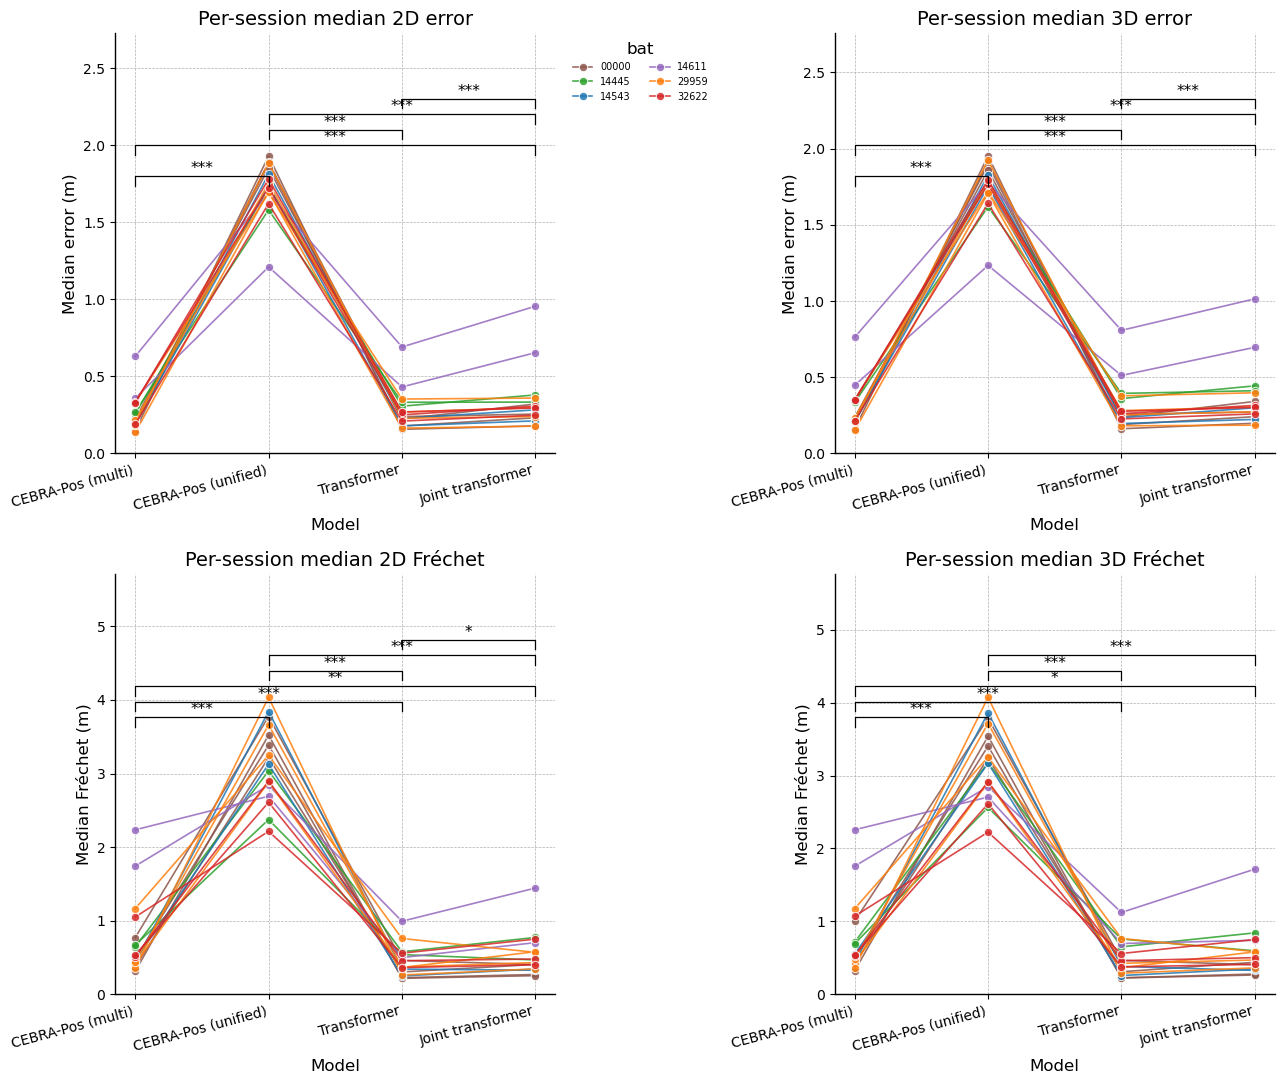

Pooled median test error (m):
               err_2d    err_3d
decoder                        
cebra_pos    0.236093  0.272760
unified      1.736478  1.766421
transformer  0.258569  0.283138
joint        0.302472  0.334435

Across-session paired Wilcoxon (3D err):
  CEBRA-Pos (multi) vs CEBRA-Pos (unified) n=17 median(diff)=+1.540 m  p=1.53e-05
  CEBRA-Pos (multi) vs Transformer  n=17 median(diff)=+0.025 m  p=0.174
  CEBRA-Pos (multi) vs Joint transformer n=17 median(diff)=+0.059 m  p=0.000839
  CEBRA-Pos (unified) vs Transformer  n=17 median(diff)=-1.518 m  p=1.53e-05
  CEBRA-Pos (unified) vs Joint transformer n=17 median(diff)=-1.493 m  p=1.53e-05
   Transformer vs Joint transformer n=17 median(diff)=+0.033 m  p=1.53e-05

Across-session paired Wilcoxon (3D Fréchet):
  CEBRA-Pos (multi) vs CEBRA-Pos (unified) n=17 median(diff)=+2.467 m  p=1.53e-05
  CEBRA-Pos (multi) vs Transformer  n=17 median(diff)=-0.112 m  p=7.63e-05
  CEBRA-Pos (multi) vs Joint transformer n=17 median(diff)=-0.098

In [37]:
from itertools import combinations
from scipy.stats import wilcoxon


def _stars(p):
    if not np.isfinite(p):
        return None
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else None


def _bracket(ax, x1, x2, y, p, h_frac=0.03):
    s = _stars(p)
    if s is None:          # hide n.s.
        return
    h = h_frac * (ax.get_ylim()[1] - ax.get_ylim()[0])
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color='k', lw=0.9)
    ax.text((x1 + x2) / 2, y + h, s, ha='center', va='bottom', fontsize=11)


def pairwise_across_session(median_df, col):
    wide = median_df.pivot(index='session', columns='decoder', values=col).dropna()
    out = {}
    for d1, d2 in combinations(DECODER_ORDER, 2):
        if d1 not in wide or d2 not in wide:
            continue
        diff = (wide[d2] - wide[d1]).values
        if np.all(diff == 0):
            out[(d1, d2)] = (np.nan, len(diff), float(np.median(diff)))
        else:
            r = wilcoxon(diff, zero_method='wilcox', alternative='two-sided')
            out[(d1, d2)] = (float(r.pvalue), len(diff), float(np.median(diff)))
    return out


METRIC_PANELS = [('err_2d', 'Per-session median 2D error', 'Median error (m)'),
                 ('err_3d', 'Per-session median 3D error', 'Median error (m)'),
                 ('frechet_2d', 'Per-session median 2D Fréchet', 'Median Fréchet (m)'),
                 ('frechet_3d', 'Per-session median 3D Fréchet', 'Median Fréchet (m)')]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()
xpos = {d: i for i, d in enumerate(DECODER_ORDER)}
for ax, (col, title, ylab) in zip(axes, METRIC_PANELS):
    sns.lineplot(data=median_per_session, x='decoder', y=col, hue='bat',
                 palette=BAT_PALETTE, units='session', estimator=None, marker='o',
                 lw=1.2, alpha=0.85, ax=ax, legend=(ax is axes[0]))
    ax.set_title(title); ax.set_ylabel(ylab); ax.set_xlabel('Model')
    ax.set_xticks(range(len(DECODER_ORDER)))
    ax.set_xticklabels([DECODER_LABEL[d] for d in DECODER_ORDER], rotation=15, ha='right')
    ax.set_ylim(bottom=0)
    if ax is axes[0]:
        ax.legend(title='bat', bbox_to_anchor=(1.02, 1.0), loc='upper left',
                  fontsize=7, frameon=False, ncol=2)
    # staggered significance brackets over every decoder pair
    pairs = pairwise_across_session(median_per_session, col)
    ytop = ax.get_ylim()[1]
    for k, ((d1, d2), (p, n, md_)) in enumerate(pairs.items()):
        _bracket(ax, xpos[d1], xpos[d2], ytop * (0.86 + 0.05 * k), p)
    ax.set_ylim(top=ytop * (1.1 + 0.05 * max(len(pairs) - 1, 0)))
plt.tight_layout(); plt.show()

print('Pooled median test error (m):')
print(all_df.groupby('decoder', observed=True)[['err_2d', 'err_3d']].median())
for col, lab in [('err_3d', '3D err'), ('frechet_3d', '3D Fréchet')]:
    print(f'\nAcross-session paired Wilcoxon ({lab}):')
    for (d1, d2), (p, n, md_) in pairwise_across_session(median_per_session, col).items():
        print(f'  {DECODER_LABEL[d1]:>12} vs {DECODER_LABEL[d2]:<12} '
              f'n={n:2d} median(diff)={md_:+.3f} m  p={p:.3g}')

### 8b. Error granularity — timepoint (Euclidean) & flight (Fréchet)

Beyond the per-session medians above, resolve decoding accuracy at two finer grains:

- **Per-timepoint** Euclidean (3D) error vs *normalized within-flight time* — does error
  grow at take-off / landing vs mid-flight?
- **Per-flight** discrete-Fréchet (3D) distance — whole-trajectory shape error, one value
  per flight, points colored by bat with session-level paired-Wilcoxon brackets.

The helper `timepoint_flight_fig` is defined here and reused verbatim in Section 12.

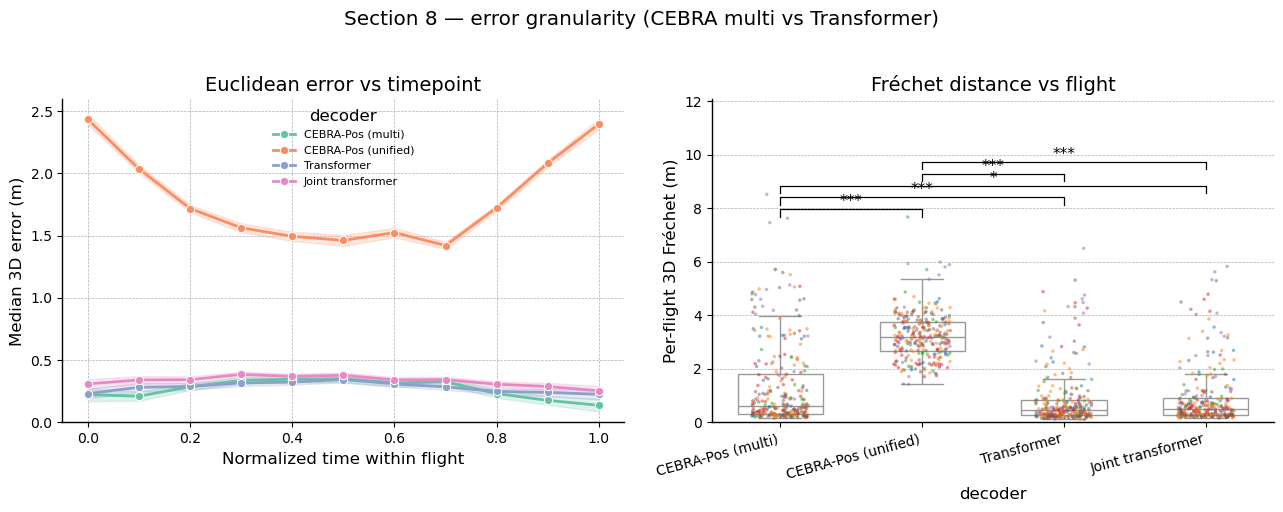

In [38]:
# --- Error granularity: per-timepoint Euclidean + per-flight Fréchet (shared helper) ---
from itertools import combinations
from scipy.stats import wilcoxon

N_TBINS = 11   # normalized within-flight time bins (0, 0.1, ..., 1.0)


def _add_tnorm(df):
    """Per-(decoder, session, flight) normalized time in [0, 1] from `t_idx`, binned."""
    df = df.copy()
    g = df.groupby(['decoder', 'session', 'flight_id'], observed=True)['t_idx']
    tmin, tmax = g.transform('min'), g.transform('max')
    df['t_norm'] = np.where(tmax > tmin, (df['t_idx'] - tmin) / (tmax - tmin), 0.0)
    df['t_bin'] = np.round(df['t_norm'] * (N_TBINS - 1)) / (N_TBINS - 1)
    return df


def _pairwise_sess(med_df, col, order):
    """Across-session paired Wilcoxon for every decoder pair (session-level)."""
    wide = med_df.pivot(index='session', columns='decoder', values=col).dropna()
    out = {}
    for d1, d2 in combinations(order, 2):
        if d1 not in wide or d2 not in wide:
            continue
        diff = (wide[d2] - wide[d1]).values
        if np.all(diff == 0):
            out[(d1, d2)] = (np.nan, len(diff), float(np.median(diff)))
        else:
            r = wilcoxon(diff, zero_method='wilcox', alternative='two-sided')
            out[(d1, d2)] = (float(r.pvalue), len(diff), float(np.median(diff)))
    return out


def timepoint_flight_fig(records_df, frechet_df, order, label_map, palette, suptitle):
    """Two panels: (a) median Euclidean 3D error vs normalized within-flight time, per
    decoder; (b) per-flight 3D Fréchet distribution per decoder (points by bat) with
    session-level paired-Wilcoxon brackets."""
    rdf = _add_tnorm(records_df)
    rdf['decoder'] = pd.Categorical(rdf['decoder'], categories=order, ordered=True)
    fdf = frechet_df.copy()
    fdf['decoder'] = pd.Categorical(fdf['decoder'], categories=order, ordered=True)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    # (a) timepoint — Euclidean error vs normalized time
    sns.lineplot(data=rdf, x='t_bin', y='err_3d', hue='decoder', hue_order=order,
                 palette=palette, estimator='median', errorbar='se', marker='o', ax=axes[0])
    axes[0].set_xlabel('Normalized time within flight')
    axes[0].set_ylabel('Median 3D error (m)')
    axes[0].set_title('Euclidean error vs timepoint'); axes[0].set_ylim(bottom=0)
    h, l = axes[0].get_legend_handles_labels()
    axes[0].legend(h, [label_map.get(x, x) for x in l], title='decoder',
                   frameon=False, fontsize=8)
    # (b) flight — per-flight 3D Fréchet distribution
    sns.boxplot(data=fdf, x='decoder', y='frechet_3d', order=order, ax=axes[1],
                showfliers=False, color='white', width=0.6)
    sns.stripplot(data=fdf, x='decoder', y='frechet_3d', order=order, hue='bat',
                  palette=BAT_PALETTE, size=2.5, alpha=0.5, jitter=0.2,
                  dodge=False, legend=False, ax=axes[1])
    axes[1].set_xticks(range(len(order)))
    axes[1].set_xticklabels([label_map.get(d, d) for d in order], rotation=15, ha='right')
    axes[1].set_xlabel('decoder'); axes[1].set_ylabel('Per-flight 3D Fréchet (m)')
    axes[1].set_title('Fréchet distance vs flight'); axes[1].set_ylim(bottom=0)
    fmed = (fdf.groupby(['bat', 'session', 'decoder'], observed=True)['frechet_3d']
            .median().reset_index())
    pairs = _pairwise_sess(fmed, 'frechet_3d', order)
    xpos = {d: i for i, d in enumerate(order)}
    ytop = axes[1].get_ylim()[1]
    for k, ((d1, d2), (p, n, md_)) in enumerate(pairs.items()):
        _bracket(axes[1], xpos[d1], xpos[d2], ytop * (0.86 + 0.05 * k), p)
    axes[1].set_ylim(top=ytop * (1.1 + 0.05 * max(len(pairs) - 1, 0)))
    fig.suptitle(suptitle, y=1.02); plt.tight_layout(); plt.show()


DECODER_PALETTE = dict(zip(DECODER_ORDER, sns.color_palette('Set2', len(DECODER_ORDER))))
timepoint_flight_fig(all_df, frechet_df, DECODER_ORDER, DECODER_LABEL, DECODER_PALETTE,
                     'Section 8 — error granularity (CEBRA multi vs Transformer)')

## 11. Persistent cohomology (topological data analysis)

Following Schneider et al. (2023, Fig. 2e–g) and the CEBRA `Demo_cohomology` notebook, we
probe the *shape* of the CEBRA embedding with persistent cohomology — `ripser` at
`maxdim=2` with prime coefficient `coeff=47` (the demo's settings). Because the models use
a cosine objective the embeddings live on the unit hypersphere, so we compute persistence
diagrams of H0 (components), H1 (loops) and H2 (voids) directly. Betti numbers follow the
demo's rule: count features whose lifespan exceeds the **shuffled-embedding null** max
lifespan per dimension × 1.1 (a 10% margin); the single infinite H0 bar is always counted
as the one connected component.

Unlike the rat 1.6 m linear track (a ring → Betti (1,1,0)), bat flight fills an open
3-D volume, so this is exploratory — we contrast CEBRA-Pos, CEBRA-Time and a shuffled
control. `ripser` at maxdim 2 is cubic in sample count, so we subsample and use the
highest-neuron sessions; tune `TDA_*` to trade speed for resolution.

In [18]:
from ripser import ripser

# Matches the CEBRA Demo_cohomology methodology: ripser persistent cohomology,
# Betti = features whose lifespan exceeds the shuffled-null max lifespan x TDA_MARGIN.
TDA_MAXDIM = 2     # H0 components, H1 loops, H2 voids
TDA_COEFF = 47     # prime cohomology coefficient (CEBRA demo uses Z/47)
TDA_SUB = 600      # subsample (demo uses 1000; ripser maxdim=2 is ~cubic in n)
TDA_SHUFFLE = 2    # shuffled-embedding null draws
TDA_MARGIN = 1.1   # demo's 10% lifespan margin over the shuffled-null max
TDA_VARIANTS = [v for v in ('cebra_pos', 'cebra_time') if v in VARIANTS]
TDA_SESSIONS = sorted(session_names, key=lambda s: unit_num_dict[s], reverse=True)[:3]
_tda_rng = np.random.default_rng(seed)


def embed_pooled(session, variant):
    flights = session_flights(session, 'train') + session_flights(session, 'test')
    X = np.vstack([f['spike'] for f in flights])
    return cebra_models[(session, variant)].transform(X)


def _sub(E):
    if len(E) <= TDA_SUB:
        return E
    return E[_tda_rng.choice(len(E), TDA_SUB, replace=False)]


def _shuffle_cols(E):
    return np.column_stack([_tda_rng.permutation(E[:, j]) for j in range(E.shape[1])])


def betti_and_dgms(E, shuffle_input=False):
    """Persistence diagrams + Betti numbers vs a column-shuffled null.
    shuffle_input=True first scrambles the embedding itself (topology control)."""
    E = _sub(E)
    if shuffle_input:
        E = _shuffle_cols(E)
    real = ripser(E, maxdim=TDA_MAXDIM, coeff=TDA_COEFF)['dgms']
    thr = [0.0] * (TDA_MAXDIM + 1)
    for _ in range(TDA_SHUFFLE):
        sh = ripser(_shuffle_cols(E), maxdim=TDA_MAXDIM, coeff=TDA_COEFF)['dgms']
        for d, dg in enumerate(sh):
            ls = dg[:, 1] - dg[:, 0]; ls = ls[np.isfinite(ls)]
            if len(ls):
                thr[d] = max(thr[d], float(ls.max()))
    betti = []
    for d, dg in enumerate(real):
        ls = dg[:, 1] - dg[:, 0]
        n_inf = int((~np.isfinite(ls)).sum())   # infinite H0 bar = the one component
        betti.append(n_inf + int((ls[np.isfinite(ls)] > thr[d] * TDA_MARGIN).sum()))
    return betti, real, thr


tda_rows, tda_dgms = [], {}
for session in TDA_SESSIONS:
    for variant in TDA_VARIANTS:
        bn, dg, thr = betti_and_dgms(embed_pooled(session, variant))
        tda_dgms[(session, variant)] = (dg, thr, bn)
        tda_rows.append(dict(session=session, bat=parse_bat(session), variant=variant,
                             H0=bn[0], H1=bn[1], H2=bn[2] if len(bn) > 2 else 0))
    print(f'{session} TDA done')

# Shuffled-embedding control on the representative (top-neuron) session.
rep = TDA_SESSIONS[0]
bn_sh, dg_sh, thr_sh = betti_and_dgms(embed_pooled(rep, 'cebra_pos'), shuffle_input=True)
tda_dgms[(rep, 'shuffled')] = (dg_sh, thr_sh, bn_sh)
tda_rows.append(dict(session=rep, bat=parse_bat(rep), variant='shuffled',
                     H0=bn_sh[0], H1=bn_sh[1], H2=bn_sh[2] if len(bn_sh) > 2 else 0))

tda_df = pd.DataFrame(tda_rows)
print('\nBetti numbers (features beating the shuffled-embedding null):')
print(tda_df.to_string(index=False))

Dataset_3_00000_240402 TDA done
Dataset_3_29959_240402 TDA done
Dataset_3_14543_240419 TDA done

Betti numbers (features beating the shuffled-embedding null):
               session   bat   variant  H0  H1  H2
Dataset_3_00000_240402 00000 cebra_pos   1   5   1
Dataset_3_29959_240402 29959 cebra_pos   1  10   2
Dataset_3_14543_240419 14543 cebra_pos   1   7   1
Dataset_3_00000_240402 00000  shuffled   1   0   0


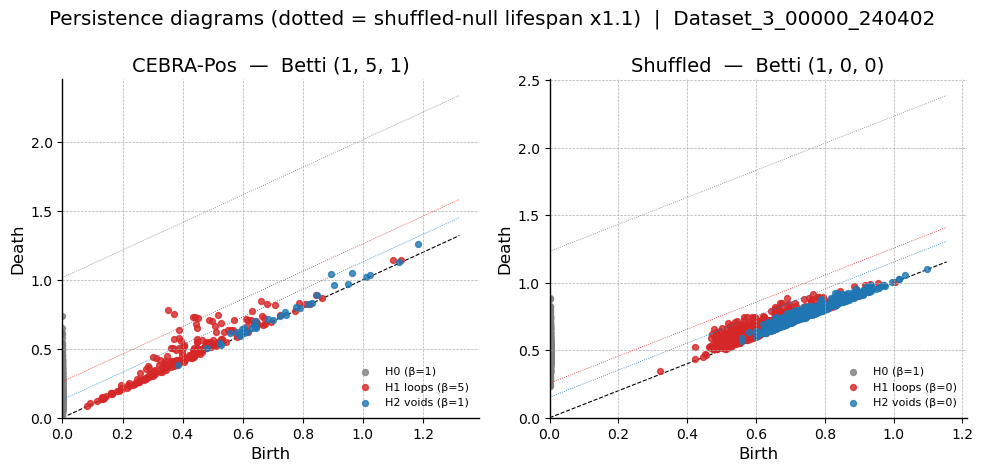

In [19]:
# Persistence diagrams for the representative session: CEBRA-Pos, CEBRA-Time, shuffled.
DIM_COLOR = {0: 'tab:gray', 1: 'tab:red', 2: 'tab:blue'}
DIM_NAME = {0: 'H0', 1: 'H1 loops', 2: 'H2 voids'}
panels = [(rep, v) for v in TDA_VARIANTS] + [(rep, 'shuffled')]
TITLE = {'cebra_pos': 'CEBRA-Pos', 'cebra_time': 'CEBRA-Time', 'shuffled': 'Shuffled'}

fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 4.8))
for ax, key in zip(axes, panels):
    dgms, thr, bn = tda_dgms[key]
    finite = [dg[np.isfinite(dg[:, 1])] for dg in dgms]
    hi = max([f[:, 1].max() for f in finite if len(f)] + [1.0]) * 1.05
    ax.plot([0, hi], [0, hi], 'k--', lw=0.8, zorder=0)
    for d, dg in enumerate(dgms):
        pts = dg[np.isfinite(dg[:, 1])]
        if len(pts):
            ax.scatter(pts[:, 0], pts[:, 1], s=18, color=DIM_COLOR[d], alpha=0.8,
                       label=f'{DIM_NAME[d]} (β={bn[d]})')
        if thr[d] > 0:   # significance band: death = birth + (null max x margin)
            t = thr[d] * TDA_MARGIN
            ax.plot([0, hi], [t, hi + t], color=DIM_COLOR[d], lw=0.6, ls=':')
    ax.set_xlabel('Birth'); ax.set_ylabel('Death'); ax.set_xlim(0); ax.set_ylim(0)
    ax.set_title(f"{TITLE[key[1]]}  —  Betti {tuple(bn)}")
    ax.legend(fontsize=8, frameon=False, loc='lower right')
fig.suptitle(f'Persistence diagrams (dotted = shuffled-null lifespan x{TDA_MARGIN})  |  {rep}')
plt.tight_layout(); plt.show()

## 12. Single- vs multi- vs unified-session CEBRA: position decoding

Following Schneider et al. (2023, Ext. Data Fig. 7, **position-decoding panel**), we contrast the
three CEBRA fitting regimes against the two supervised transformers, all read out per session as
**paired lineplots** with the mean ± SEM overlaid:

- **single CEBRA** — independent per-session models (one latent space each);
- **multi CEBRA** (`multi_model`, §4) — one encoder *per* session into a shared, session-invariant
  space;
- **unified CEBRA** (`unified_model`, §4b) — ONE shared encoder over the neuron-concatenation of all
  sessions.

All three CEBRA embeddings are decoded with the **kNN** read-out (cosine `KNeighborsRegressor`,
matching §6/§8), so the supervised transformers (the original `Bat_Transformer_Decoder` and the joint
masked transformer) sit directly alongside them. We report per-session medians of **both** Euclidean
error and **3D Fréchet** distance (paired Wilcoxon per panel), then resolve accuracy at finer grain
with `timepoint_flight_fig` (shared with §8): per-timepoint Euclidean error vs normalized within-flight
time, and per-flight 3D Fréchet distance.

In [39]:
from scipy.stats import wilcoxon

# Build single + multi + unified CEBRA decode records (kNN read-out, via the §8 helper) so all three
# fitting regimes can be quantified at timepoint / flight / session granularity alongside the two
# supervised transformers. Unified is embedded whole-stream then sliced per flight (§4b).
ORDER12 = ['single', 'multi', 'unified', 'transformer', 'joint']
LABEL12 = {'single': 'single CEBRA', 'multi': 'multi CEBRA', 'unified': 'unified CEBRA',
           'transformer': 'Transformer', 'joint': 'Joint transformer'}
PAL12 = dict(zip(ORDER12, sns.color_palette('Set2', len(ORDER12))))

uni_tr = unified_embed_split(unified_model, 'train')
uni_te = unified_embed_split(unified_model, 'test')

dec_rows, dec_records = [], []
for i, s in enumerate(session_names):
    tr, te = _multi_train[s], session_flights(s, 'test')
    s_tr = embed_flights(cebra_models[(s, MULTI_VARIANT)], tr)
    s_te = embed_flights(cebra_models[(s, MULTI_VARIANT)], te)
    m_tr = embed_flights_multi(multi_model, tr, i)
    m_te = embed_flights_multi(multi_model, te, i)
    for tag, etr, ete in [('single', s_tr, s_te), ('multi', m_tr, m_te),
                          ('unified', uni_tr[s], uni_te[s])]:
        recs, _ = _decode_from_embeds(s, etr, ete, tag)   # kNN read-out -> per-timepoint recs
        dec_records.extend(recs)
        dec_rows.append(dict(session=s, bat=parse_bat(s), training=tag,
                             err_cm=float(np.median([r['err_3d'] for r in recs])) * 100))
dec_df = pd.DataFrame(dec_rows)

# Long per-timepoint records (single, multi, unified, transformer, joint) + per-flight 3D Fréchet,
# so §12 mirrors §8's timepoint / flight / session views.
dec_records_df = pd.concat(
    [pd.DataFrame(dec_records), transformer_df[transformer_df.session.isin(session_names)],
     joint_df[joint_df.session.isin(session_names)]],
    ignore_index=True)
frechet12_df = compute_frechet_per_flight(dec_records_df, ORDER12)

_med = lambda t: dec_df[dec_df.training == t].set_index('session').err_cm
dpv = wilcoxon(_med('multi'), _med('single')).pvalue
print(f'decoding err (cm): single {_med("single").median():.1f}  ->  '
      f'multi {_med("multi").median():.1f}  ->  unified {_med("unified").median():.1f}  '
      f'(paired Wilcoxon multi vs single two-sided p={dpv:.3g})')

decoding err (cm): single 23.6  ->  multi 23.4  ->  unified 178.7  (paired Wilcoxon multi vs single two-sided p=0.712)


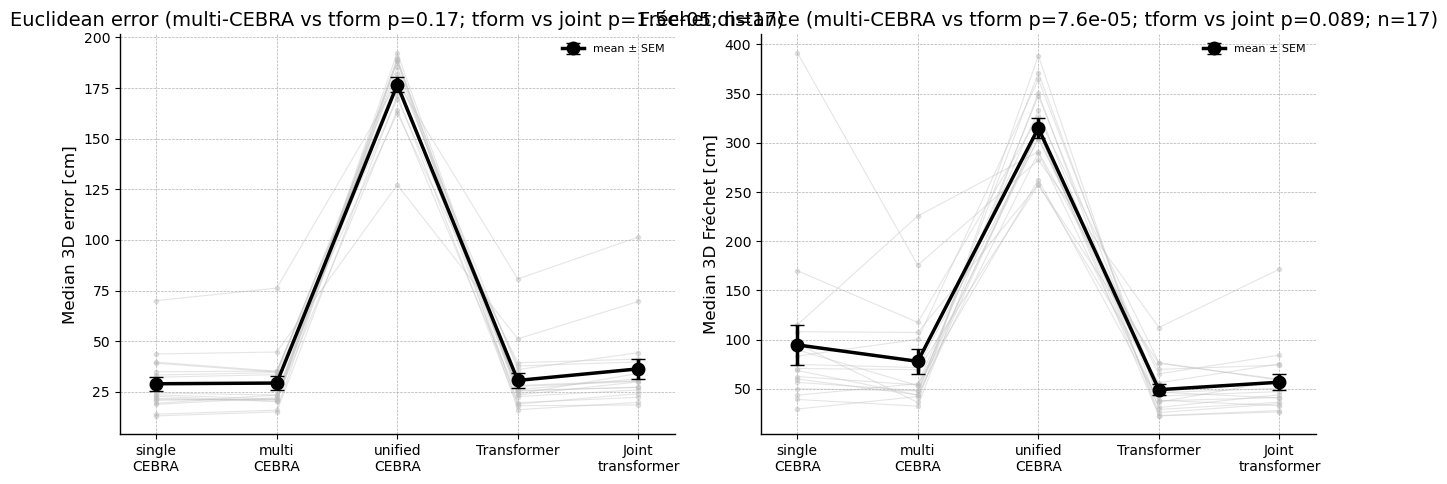

                   decode_err_cm  frechet_3d_cm
single CEBRA           29.017512      94.724101
multi CEBRA            29.359578      77.993737
unified CEBRA         176.599719     315.068297
Transformer            30.665170      49.208731
Joint transformer      36.369056      56.801553


In [40]:
# Paired lineplots (Fig 7a-style) with the mean +/- SEM overlaid: per-session decoding error and
# 3D Fréchet across single / multi / unified CEBRA + BOTH supervised transformers.
def _paired_lineplot(ax, series, ylabel, title):
    """series: ordered dict {label: row-aligned values}. Faint per-item lines across
    all conditions + bold mean +/- SEM."""
    labels = list(series)
    M = np.column_stack([np.asarray(series[k], float) for k in labels])  # (n_items, n_cond)
    xs = np.arange(len(labels))
    for row in M:
        ax.plot(xs, row, color='0.75', lw=0.8, alpha=0.4, marker='o', ms=3, zorder=1)
    mean = M.mean(0); sem = M.std(0, ddof=1) / np.sqrt(len(M))
    ax.errorbar(xs, mean, yerr=sem, color='k', lw=2.5, marker='o', ms=9, capsize=5,
                zorder=3, label='mean ± SEM')
    ax.set_xticks(xs); ax.set_xticklabels(labels)
    ax.set_xlim(-0.3, len(labels) - 0.7); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend(frameon=False, fontsize=8, loc='best')

SHORT12 = {'single': 'single\nCEBRA', 'multi': 'multi\nCEBRA', 'unified': 'unified\nCEBRA',
           'transformer': 'Transformer', 'joint': 'Joint\ntransformer'}
# Per-session medians (cm) for each non-CEBRA decoder, keyed like dec_df's pivot.
sup_cm = {'transformer': transformer_df.groupby('session')['err_3d'].median() * 100,
          'joint': joint_df.groupby('session')['err_3d'].median() * 100}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

dwide = dec_df.pivot(index='session', columns='training', values='err_cm')
for d, v in sup_cm.items():
    dwide[d] = v.reindex(dwide.index)
dwide = dwide[ORDER12].dropna()
p_mt = wilcoxon(dwide['multi'], dwide['transformer']).pvalue       # multi-CEBRA vs Transformer
p_tj = wilcoxon(dwide['transformer'], dwide['joint']).pvalue       # Transformer vs joint
_paired_lineplot(
    axes[0], {SHORT12[d]: dwide[d] for d in ORDER12}, 'Median 3D error [cm]',
    f'Euclidean error (multi-CEBRA vs tform p={p_mt:.2g}; '
    f'tform vs joint p={p_tj:.2g}; n={len(dwide)})')

fwide = (frechet12_df.groupby(['session', 'decoder'], observed=True)['frechet_3d']
         .median().unstack('decoder')[ORDER12] * 100).dropna()
pf_mt = wilcoxon(fwide['multi'], fwide['transformer']).pvalue
pf_tj = wilcoxon(fwide['transformer'], fwide['joint']).pvalue
_paired_lineplot(
    axes[1], {SHORT12[d]: fwide[d] for d in ORDER12}, 'Median 3D Fréchet [cm]',
    f'Fréchet distance (multi-CEBRA vs tform p={pf_mt:.2g}; '
    f'tform vs joint p={pf_tj:.2g}; n={len(fwide)})')
plt.tight_layout(); plt.show()

print(pd.DataFrame({
    'decode_err_cm': dwide[ORDER12].mean().values,
    'frechet_3d_cm': fwide[ORDER12].mean().values,
}, index=[LABEL12[d] for d in ORDER12]))

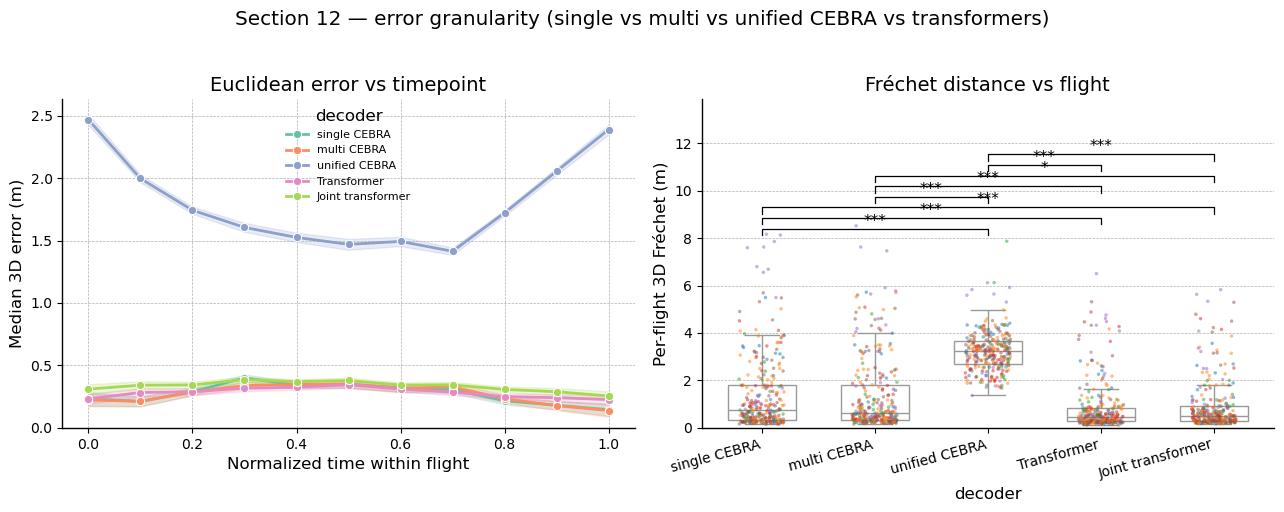

In [41]:
# Section 12 — same error granularity (timepoint Euclidean + flight Fréchet) for
# single / multi / unified CEBRA + both transformers, via the Section 8b helper.
timepoint_flight_fig(dec_records_df, frechet12_df, ORDER12, LABEL12, PAL12,
                     'Section 12 — error granularity (single vs multi vs unified CEBRA vs transformers)')

## Summary

- **Metric A** quantifies how much position a *linear* read-out can recover from each
  embedding, in directly comparable meters/Fréchet units, against the supervised
  Transformer (expected to be the strongest). A kNN (`KNeighborsRegressor`, cosine)
  read-out is reported alongside.
- **Section 5** writes an interactive HTML viewer (true behaviour + CEBRA single/multi/unified,
  plus the Transformer once built) right after the fits — recolourable by position / kinematics /
  route — to eyeball embedding quality before the rest of the pipeline.
- **Section 11** reads the topology of the embedding (persistent cohomology / Betti
  numbers) vs a shuffled null, matching the CEBRA Demo_cohomology.
- **Section 12** compares the three CEBRA fitting regimes — **single vs multi vs unified** — against
  both supervised transformers on position decoding (Euclidean error + 3D Fréchet, Ext. Data Fig. 7
  position-decoding panel).